In [12]:
import sys
import site

user_site = site.getusersitepackages()
if user_site not in sys.path:
    sys.path.append(user_site)

import ee

In [5]:
%pip install earthengine-api

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.8/16.8 MB 61.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15/15 [earthengine-api] [earthengine-api]rage]ent]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opentelemetry-proto 1.34.1 requires protobuf<6.0,>=5.0, but you have protobuf 6.33.6 which is incompatible.
opentelemetry-semantic-conventions 0.55b1 requires opentelemetry-api==1.34.1, but you have opentelemetry-api 1.45.2 which is incompatible.
autogen-core 0.7.5 requires protobuf~=5.29.3, but you have protobuf 6.33.6 which is incompatible.
opentelemetry-sdk 1.34.1 requires opentelemetry-api==1.34.1, but you have opentelemetry-api 1.45.2 which is incompatible.
crewai 1.7.2 requires opentelemetry-api~=1.34.0, but you have opentelemetry-api 1.45.2 which is i

In [6]:
import ee

# Replace the text between quotes with your actual Google Cloud project ID.
PROJECT_ID = "lulc-sentinel1-project"

# Follow the authentication link printed below this cell.
# Sign in with the Google account that has Earth Engine access.
ee.Authenticate(auth_mode="notebook")

# Connect and make a small request to verify access.
ee.Initialize(project=PROJECT_ID)

print("Earth Engine connection successful:", ee.Number(1).getInfo())

/home/jovyan/.local/lib/python3.11/site-packages/google/api_core/_python_package_support.py:206: FutureWarning: Package google.api_core depends on grpcio, currently installed at version 1.74.0. grpcio < 1.83.0 does not support Post-Quantum Cryptography (PQC). Support for non-PQC environments is deprecated. In April 2027, Google Cloud Python packages will raise their minimum requirements (including google-api-core, grpcio, and grpcio-status) to enforce grpcio >= 1.83.0. For more details on Google Cloud's post-quantum security migration, visit: https://cloud.google.com/security/resources/post-quantum-cryptography
  warnings.warn(


Enter verification code:  4/1AUn6Hd_8c6ZnTV1UFGMDqr_lmzTGxcVAjXrIqQeBQOl-peYFAmqZRBiNbpQ



Successfully saved authorization token.
Earth Engine connection successful: 1


In [7]:
import ee

# Request fresh credentials.
ee.Authenticate(auth_mode="notebook", force=True)

Enter verification code:  4/1AUn6Hd_3NNzaToW42VGWdq8Y_zRJ1U2W1Qwi8DOA1aNFEMLjI7GLxRmpLIk



Successfully saved authorization token.


In [8]:
import ee

# Your Google Cloud project ID.
PROJECT_ID = "lulc-sentinel1-project"

# Use the authorization you have already completed.
ee.Initialize(project=PROJECT_ID)

# Check that Earth Engine responds.
print("Earth Engine connection successful:", ee.Number(1).getInfo())

Earth Engine connection successful: 1


In [11]:
import sys
import subprocess

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

print("\nChecking earthengine-api package:")
result = subprocess.run(
    [sys.executable, "-m", "pip", "show", "earthengine-api"],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("stderr:")
    print(result.stderr)

Python executable:
/usr/bin/python3

Python version:
3.11.13 (main, Jun  4 2025, 08:57:29) [GCC 11.4.0]

Checking earthengine-api package:
Name: earthengine-api
Version: 1.7.51
Summary: Earth Engine Python API
Home-page: http://code.google.com/p/earthengine-api
Author: 
Author-email: Google LLC <noreply@google.com>
License: Apache-2.0
Location: /home/jovyan/.local/lib/python3.11/site-packages
Requires: google-api-python-client, google-auth, google-auth-httplib2, google-cloud-storage, httplib2, requests
Required-by: 



In [12]:
import sys
import site

user_site = site.getusersitepackages()

print("Python:")
print(sys.executable)

print("\nUser site-packages:")
print(user_site)

print("\nUser site enabled:")
print(site.ENABLE_USER_SITE)

if user_site not in sys.path:
    sys.path.append(user_site)

print("\nUser site added to Python path.")

import ee

print("\nEarth Engine API imported successfully.")
print("Earth Engine version:", ee.__version__)

Python:
/usr/bin/python3

User site-packages:
/home/jovyan/.local/lib/python3.11/site-packages

User site enabled:
True

User site added to Python path.

Earth Engine API imported successfully.
Earth Engine version: 1.7.51


In [13]:
# ============================================================
# EARTH ENGINE CONNECTION CHECK
# ============================================================

import ee

ee.Initialize(project="lulc-sentinel1-project")

print("Earth Engine connection successful:", ee.Number(1).getInfo())

Earth Engine connection successful: 1


In [16]:
import sys
import site

user_site = site.getusersitepackages()
if user_site not in sys.path:
    sys.path.append(user_site)

import ee

In [20]:
# ============================================================
# CELL 6 — CREATE AND DOWNLOAD MODEL-TEST RASTER
# ============================================================

import ee
import requests
import rasterio
from pathlib import Path
import numpy as np

# ------------------------------------------------------------
# OUTPUT DIRECTORY
# ------------------------------------------------------------

output_dir = Path(
    "/home/jovyan/vault/DeepLearningPro/results/prototype_test"
)
output_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# RECREATE THE SENTINEL-1 COLLECTION
# ------------------------------------------------------------

start_date = ee.Date.fromYMD(YEAR, MONTH, 1)
end_date = start_date.advance(1, "month")

point = ee.Geometry.Point(
    [LONGITUDE, LATITUDE]
)

region = point.buffer(
    HALF_WIDTH_METERS
).bounds()

collection_test = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterBounds(region)
    .filterDate(start_date, end_date)
    .filter(
        ee.Filter.listContains(
            "transmitterReceiverPolarisation",
            "VV"
        )
    )
    .filter(
        ee.Filter.listContains(
            "transmitterReceiverPolarisation",
            "VH"
        )
    )
    .filter(
        ee.Filter.eq("instrumentMode", "IW")
    )
    .filter(
        ee.Filter.eq("orbitProperties_pass", "ASCENDING")
    )
    .filter(
        ee.Filter.eq("relativeOrbitNumber_start", 1)
    )
)

count = collection_test.size().getInfo()

print("=" * 60)
print("MODEL-TEST SENTINEL-1 COLLECTION")
print("=" * 60)
print(f"Images selected: {count}")

if count == 0:
    raise RuntimeError(
        "No ascending relative-orbit-1 images found."
    )

# ------------------------------------------------------------
# CREATE MONTHLY COMPOSITE
# ------------------------------------------------------------

monthly_image = (
    collection_test
    .select(["VV", "VH"])
    .median()
    .clip(region)
)

print(
    "Bands:",
    monthly_image.bandNames().getInfo()
)

# ------------------------------------------------------------
# DOWNLOAD GEO-TIFF
# ------------------------------------------------------------

output_file = output_dir / (
    f"lagos_{YEAR}_{MONTH:02d}_"
    "ascending_orbit1_VV_VH.tif"
)

download_url = monthly_image.getDownloadURL({
    "name": output_file.stem,
    "region": region,
    "scale": 10,
    "format": "GEO_TIFF"
})

response = requests.get(
    download_url,
    timeout=120
)

response.raise_for_status()

output_file.write_bytes(response.content)

print(f"\nDownloaded:")
print(output_file)

# ------------------------------------------------------------
# INSPECT RASTER
# ------------------------------------------------------------

with rasterio.open(output_file) as src:

    print("\nRaster information:")
    print(f"Width:       {src.width}")
    print(f"Height:      {src.height}")
    print(f"Bands:       {src.count}")
    print(f"CRS:         {src.crs}")
    print(f"Data type:   {src.dtypes}")
    print(f"Bounds:      {src.bounds}")
    print(f"Resolution:  {src.res}")

    vv = src.read(1)
    vh = src.read(2)

print("\nRaw raster ranges:")

print(
    f"VV: min={np.nanmin(vv):.4f}, "
    f"max={np.nanmax(vv):.4f}"
)

print(
    f"VH: min={np.nanmin(vh):.4f}, "
    f"max={np.nanmax(vh):.4f}"
)

print("\nRaster download and inspection completed.")

MODEL-TEST SENTINEL-1 COLLECTION
Images selected: 3
Bands: ['VV', 'VH']

Downloaded:
/home/jovyan/vault/DeepLearningPro/results/prototype_test/lagos_2025_01_ascending_orbit1_VV_VH.tif

Raster information:
Width:       501
Height:      502
Bands:       2
CRS:         EPSG:4326
Data type:   ('float64', 'float64')
Bounds:      BoundingBox(left=3.3567347221694157, bottom=6.501826363400273, right=3.401740317903804, top=6.546921790663073)
Resolution:  (8.983152841195215e-05, 8.983152841195215e-05)

Raw raster ranges:
VV: min=-27.9718, max=22.1598
VH: min=-42.7163, max=17.8517

Raster download and inspection completed.


In [21]:
# ============================================================
# CELL 7 — APPLY TRAINING PREPROCESSING
# ============================================================

import numpy as np
import rasterio
from pathlib import Path

# ------------------------------------------------------------
# FIND THE DOWNLOADED RASTER
# ------------------------------------------------------------

raster_files = sorted(
    output_dir.glob("*.tif")
)

if not raster_files:
    raise FileNotFoundError(
        f"No GeoTIFF found in {output_dir}"
    )

raster_path = raster_files[-1]

print("Using raster:")
print(raster_path)

# ------------------------------------------------------------
# READ VV / VH
# ------------------------------------------------------------

with rasterio.open(raster_path) as src:
    vv = src.read(1).astype(np.float32)
    vh = src.read(2).astype(np.float32)

    raster_width = src.width
    raster_height = src.height

print("\nOriginal raster:")
print(f"Width:  {raster_width}")
print(f"Height: {raster_height}")
print(f"Shape:  {vv.shape}")

# ------------------------------------------------------------
# TRAINING PREPROCESSING
# ------------------------------------------------------------
# Sentinel-1 training preprocessing:
#
# 1. Clip dB values to [-25, 0]
# 2. Normalize:
#       (x + 25) / 25
#
# Do NOT convert to dB again.
# ------------------------------------------------------------

vv_clipped = np.clip(vv, -25.0, 0.0)
vh_clipped = np.clip(vh, -25.0, 0.0)

vv_normalized = (vv_clipped + 25.0) / 25.0
vh_normalized = (vh_clipped + 25.0) / 25.0

# ------------------------------------------------------------
# CREATE MODEL INPUT
# ------------------------------------------------------------

model_input = np.stack(
    [vv_normalized, vh_normalized],
    axis=0
).astype(np.float32)

print("\nModel input:")
print(f"Shape: {model_input.shape}")
print(f"Dtype: {model_input.dtype}")

print("\nExpected format:")
print("(2, H, W)")

print("\nNormalized value ranges:")

print(
    f"VV: min={vv_normalized.min():.6f}, "
    f"max={vv_normalized.max():.6f}"
)

print(
    f"VH: min={vh_normalized.min():.6f}, "
    f"max={vh_normalized.max():.6f}"
)

# ------------------------------------------------------------
# FINAL CHECK
# ------------------------------------------------------------

assert model_input.ndim == 3
assert model_input.shape[0] == 2
assert model_input.dtype == np.float32

assert np.isfinite(model_input).all()

assert model_input.min() >= 0.0
assert model_input.max() <= 1.0

print("\n" + "=" * 60)
print("MODEL INPUT PREPROCESSING CHECK PASSED")
print("=" * 60)

Using raster:
/home/jovyan/vault/DeepLearningPro/results/prototype_test/lagos_2025_01_ascending_orbit1_VV_VH.tif

Original raster:
Width:  501
Height: 502
Shape:  (502, 501)

Model input:
Shape: (2, 502, 501)
Dtype: float32

Expected format:
(2, H, W)

Normalized value ranges:
VV: min=0.000000, max=1.000000
VH: min=0.000000, max=1.000000

MODEL INPUT PREPROCESSING CHECK PASSED


In [22]:


# ============================================================
# CELL 8 — VERIFY TRAINING PATCH SIZE
# ============================================================

import sys
import site
from pathlib import Path

# Make the project modules available
project_dir = Path(
    "/home/jovyan/vault/DeepLearningPro"
)

if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

# Make user-installed packages available
user_site = site.getusersitepackages()

if user_site not in sys.path:
    sys.path.append(user_site)

# ------------------------------------------------------------
# IMPORT EXISTING DATASET CLASS
# ------------------------------------------------------------

from lulc_dataset import LULCDataset

# ------------------------------------------------------------
# LOAD ONE TRAINING SAMPLE
# ------------------------------------------------------------

train_dataset = LULCDataset(
    project_dir,
    split="train",
    augment=False
)

sample = train_dataset[0]

training_image = sample["image"]
training_target = sample["target"]

print("=" * 60)
print("TRAINING PATCH SHAPE CHECK")
print("=" * 60)

print(f"Number of training samples: {len(train_dataset)}")

print("\nTraining image:")
print(f"Shape: {training_image.shape}")
print(f"Dtype: {training_image.dtype}")

print("\nTraining target:")
print(f"Shape: {training_target.shape}")
print(f"Dtype: {training_target.dtype}")

print("\nModel input channels:")
print(training_image.shape[0])

print("\nSpatial patch size:")
print(
    f"Height = {training_image.shape[1]}"
)
print(
    f"Width  = {training_image.shape[2]}"
)

print("\n" + "=" * 60)
print("PATCH SIZE VERIFIED FROM EXISTING TRAINING DATASET")
print("=" * 60)


TRAINING PATCH SHAPE CHECK
Number of training samples: 21782

Training image:
Shape: torch.Size([2, 256, 256])
Dtype: torch.float32

Training target:
Shape: torch.Size([256, 256])
Dtype: torch.int64

Model input channels:
2

Spatial patch size:
Height = 256
Width  = 256

PATCH SIZE VERIFIED FROM EXISTING TRAINING DATASET


In [23]:
# ============================================================
# CELL 9 — CHECK RASTER TILING GEOMETRY
# ============================================================

PATCH_SIZE = 256

height, width = model_input.shape[1:]

full_height_patches = height // PATCH_SIZE
full_width_patches = width // PATCH_SIZE

used_height = full_height_patches * PATCH_SIZE
used_width = full_width_patches * PATCH_SIZE

remaining_height = height - used_height
remaining_width = width - used_width

print("=" * 60)
print("RASTER TILING CHECK")
print("=" * 60)

print(f"Raster size:       {height} × {width}")
print(f"Model patch size:  {PATCH_SIZE} × {PATCH_SIZE}")

print("\nComplete patches:")
print(f"Vertical:   {full_height_patches}")
print(f"Horizontal: {full_width_patches}")

print("\nArea covered by complete patches:")
print(f"Height: {used_height}")
print(f"Width:  {used_width}")

print("\nRemaining pixels:")
print(f"Bottom: {remaining_height}")
print(f"Right:  {remaining_width}")

print("\nPotential complete patches:")
print(
    f"{full_height_patches * full_width_patches}"
)

print("=" * 60)

RASTER TILING CHECK
Raster size:       502 × 501
Model patch size:  256 × 256

Complete patches:
Vertical:   1
Horizontal: 1

Area covered by complete patches:
Height: 256
Width:  256

Remaining pixels:
Bottom: 246
Right:  245

Potential complete patches:
1


In [24]:
# ============================================================
# CELL 10 — CREATE OVERLAPPING 256×256 MODEL PATCHES
# ============================================================

import numpy as np

PATCH_SIZE = 256
STRIDE = 128

height, width = model_input.shape[1:]

# ------------------------------------------------------------
# CALCULATE PATCH START POSITIONS
# ------------------------------------------------------------

def get_starts(length, patch_size, stride):
    starts = list(range(0, length - patch_size + 1, stride))

    # Ensure the final patch reaches the image boundary
    final_start = length - patch_size

    if starts[-1] != final_start:
        starts.append(final_start)

    return starts


row_starts = get_starts(
    height,
    PATCH_SIZE,
    STRIDE
)

col_starts = get_starts(
    width,
    PATCH_SIZE,
    STRIDE
)

print("=" * 60)
print("OVERLAPPING PATCH GENERATION")
print("=" * 60)

print(f"Raster:        {height} × {width}")
print(f"Patch size:    {PATCH_SIZE} × {PATCH_SIZE}")
print(f"Stride:        {STRIDE}")

print("\nRow starts:")
print(row_starts)

print("\nColumn starts:")
print(col_starts)

# ------------------------------------------------------------
# EXTRACT PATCHES
# ------------------------------------------------------------

patches = []
patch_locations = []

for row in row_starts:
    for col in col_starts:

        patch = model_input[
            :,
            row:row + PATCH_SIZE,
            col:col + PATCH_SIZE
        ]

        # Safety check
        assert patch.shape == (
            2,
            PATCH_SIZE,
            PATCH_SIZE
        )

        patches.append(patch)
        patch_locations.append((row, col))

patches = np.stack(patches)

print("\nNumber of patches:")
print(len(patches))

print("\nPatch tensor shape:")
print(patches.shape)

print("\nPatch locations:")
for i, location in enumerate(patch_locations):
    print(f"{i}: row={location[0]}, col={location[1]}")

print("\n" + "=" * 60)
print("PATCH GENERATION COMPLETED")
print("=" * 60)

OVERLAPPING PATCH GENERATION
Raster:        502 × 501
Patch size:    256 × 256
Stride:        128

Row starts:
[0, 128, 246]

Column starts:
[0, 128, 245]

Number of patches:
9

Patch tensor shape:
(9, 2, 256, 256)

Patch locations:
0: row=0, col=0
1: row=0, col=128
2: row=0, col=245
3: row=128, col=0
4: row=128, col=128
5: row=128, col=245
6: row=246, col=0
7: row=246, col=128
8: row=246, col=245

PATCH GENERATION COMPLETED


In [25]:
# ============================================================
# CELL 11 — LOAD TRAINED MODEL
# ============================================================

import sys
import site
from pathlib import Path
import torch

# ------------------------------------------------------------
# PROJECT PATH
# ------------------------------------------------------------

project_dir = Path(
    "/home/jovyan/vault/DeepLearningPro"
)

if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

user_site = site.getusersitepackages()

if user_site not in sys.path:
    sys.path.append(user_site)

# ------------------------------------------------------------
# IMPORT EXISTING MODEL
# ------------------------------------------------------------

from lulc_model import SmallUNet

# ------------------------------------------------------------
# MODEL CONFIGURATION
# ------------------------------------------------------------

NUM_CLASSES = 9
IN_CHANNELS = 2

model = SmallUNet(
    num_classes=NUM_CLASSES,
    in_channels=IN_CHANNELS
)

# ------------------------------------------------------------
# LOAD EXISTING BEST CHECKPOINT
# ------------------------------------------------------------

checkpoint_path = (
    project_dir
    / "results"
    / "winter9_20261106_094944_502500"
    / "best_model.pt"
)

print("=" * 60)
print("LOADING TRAINED MODEL")
print("=" * 60)

print("Checkpoint:")
print(checkpoint_path)

if not checkpoint_path.exists():
    raise FileNotFoundError(
        f"Checkpoint not found: {checkpoint_path}"
    )

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu"
)

# Handle either a raw state_dict or a checkpoint dictionary
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
else:
    state_dict = checkpoint

model.load_state_dict(state_dict)

model.eval()

# ------------------------------------------------------------
# MODEL SUMMARY
# ------------------------------------------------------------

parameter_count = sum(
    p.numel()
    for p in model.parameters()
)

print("\nModel:")
print(model)

print("\nParameters:")
print(f"{parameter_count:,}")

print("\nInput channels:")
print(IN_CHANNELS)

print("Output classes:")
print(NUM_CLASSES)

print("\nModel loaded successfully.")

LOADING TRAINED MODEL
Checkpoint:
/home/jovyan/vault/DeepLearningPro/results/winter9_20261106_094944_502500/best_model.pt

Model:
SmallUNet(
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (encoder1): ConvBlock(
    (layers): Sequential(
      (0): Conv2d(2, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): GroupNorm(8, 32, eps=1e-05, affine=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): GroupNorm(8, 32, eps=1e-05, affine=True)
      (5): ReLU(inplace=True)
    )
  )
  (encoder2): ConvBlock(
    (layers): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): GroupNorm(8, 64, eps=1e-05, affine=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): GroupNorm(8, 64, eps=1e-05, affine=True)
      (5)

In [26]:
# ============================================================
# CELL 12 — RUN MODEL INFERENCE ON REAL SENTINEL-1 PATCHES
# ============================================================

import torch
import numpy as np

# ------------------------------------------------------------
# PREPARE PATCH TENSOR
# ------------------------------------------------------------

patch_tensor = torch.from_numpy(
    patches
).float()

print("=" * 60)
print("MODEL INFERENCE")
print("=" * 60)

print("Input tensor:")
print(f"Shape: {patch_tensor.shape}")
print(f"Dtype: {patch_tensor.dtype}")

# Expected:
# [9, 2, 256, 256]

assert patch_tensor.shape == (
    len(patches),
    2,
    256,
    256
)

# ------------------------------------------------------------
# RUN INFERENCE
# ------------------------------------------------------------

with torch.no_grad():

    logits = model(
        patch_tensor
    )

    predictions = torch.argmax(
        logits,
        dim=1
    )

# ------------------------------------------------------------
# CONVERT TO NUMPY
# ------------------------------------------------------------

predictions = predictions.cpu().numpy()

# ------------------------------------------------------------
# CHECK OUTPUT
# ------------------------------------------------------------

print("\nModel output:")
print(f"Logits shape:       {tuple(logits.shape)}")
print(f"Prediction shape:   {predictions.shape}")
print(f"Prediction dtype:   {predictions.dtype}")

print("\nExpected prediction shape:")
print(
    f"({len(patches)}, 256, 256)"
)

# ------------------------------------------------------------
# CHECK PREDICTED CLASS VALUES
# ------------------------------------------------------------

unique_classes = np.unique(
    predictions
)

print("\nPredicted class IDs:")
print(unique_classes)

print(
    "\nMinimum predicted class:",
    predictions.min()
)

print(
    "Maximum predicted class:",
    predictions.max()
)

# ------------------------------------------------------------
# CLASS PIXEL COUNTS
# ------------------------------------------------------------

print("\nPredicted pixel counts:")

for class_id in range(NUM_CLASSES):

    count = np.sum(
        predictions == class_id
    )

    percentage = (
        100.0 * count / predictions.size
    )

    print(
        f"Class {class_id}: "
        f"{count:,} pixels "
        f"({percentage:.2f}%)"
    )

# ------------------------------------------------------------
# SAFETY CHECK
# ------------------------------------------------------------

assert predictions.ndim == 3

assert predictions.shape == (
    len(patches),
    256,
    256
)

assert predictions.min() >= 0
assert predictions.max() < NUM_CLASSES

print("\n" + "=" * 60)
print("REAL SENTINEL-1 MODEL INFERENCE COMPLETED")
print("=" * 60)

MODEL INFERENCE
Input tensor:
Shape: torch.Size([9, 2, 256, 256])
Dtype: torch.float32

Model output:
Logits shape:       (9, 9, 256, 256)
Prediction shape:   (9, 256, 256)
Prediction dtype:   int64

Expected prediction shape:
(9, 256, 256)

Predicted class IDs:
[2 4 5 6 8]

Minimum predicted class: 2
Maximum predicted class: 8

Predicted pixel counts:
Class 0: 0 pixels (0.00%)
Class 1: 0 pixels (0.00%)
Class 2: 3 pixels (0.00%)
Class 3: 0 pixels (0.00%)
Class 4: 230 pixels (0.04%)
Class 5: 8 pixels (0.00%)
Class 6: 588,670 pixels (99.80%)
Class 7: 0 pixels (0.00%)
Class 8: 913 pixels (0.15%)

REAL SENTINEL-1 MODEL INFERENCE COMPLETED


In [27]:
# ============================================================
# CELL 13 — RECONSTRUCT FULL RASTER PREDICTION
# ============================================================

import numpy as np
import torch

# ------------------------------------------------------------
# INITIALIZE ACCUMULATORS
# ------------------------------------------------------------

num_classes = NUM_CLASSES

logit_sum = np.zeros(
    (num_classes, height, width),
    dtype=np.float32
)

coverage_count = np.zeros(
    (height, width),
    dtype=np.float32
)

# ------------------------------------------------------------
# ACCUMULATE LOGITS FROM OVERLAPPING PATCHES
# ------------------------------------------------------------

patch_logits = logits.detach().cpu().numpy()

for patch_index, (row, col) in enumerate(
    patch_locations
):

    patch_logit = patch_logits[
        patch_index
    ]

    logit_sum[
        :,
        row:row + PATCH_SIZE,
        col:col + PATCH_SIZE
    ] += patch_logit

    coverage_count[
        row:row + PATCH_SIZE,
        col:col + PATCH_SIZE
    ] += 1

# ------------------------------------------------------------
# CHECK COVERAGE
# ------------------------------------------------------------

print("=" * 60)
print("FULL RASTER RECONSTRUCTION")
print("=" * 60)

print(
    "Raster shape:",
    (height, width)
)

print(
    "Minimum pixel coverage:",
    int(coverage_count.min())
)

print(
    "Maximum pixel coverage:",
    int(coverage_count.max())
)

if np.any(coverage_count == 0):
    raise RuntimeError(
        "Some raster pixels were not covered by any patch."
    )

# ------------------------------------------------------------
# AVERAGE OVERLAPPING LOGITS
# ------------------------------------------------------------

mean_logits = (
    logit_sum /
    coverage_count[np.newaxis, :, :]
)

# ------------------------------------------------------------
# FINAL PIXEL-LEVEL PREDICTION
# ------------------------------------------------------------

full_prediction = np.argmax(
    mean_logits,
    axis=0
).astype(np.uint8)

print("\nFull prediction shape:")
print(full_prediction.shape)

print("\nPredicted classes:")
print(np.unique(full_prediction))

# ------------------------------------------------------------
# CALCULATE UNIQUE-PIXEL CLASS PERCENTAGES
# ------------------------------------------------------------

total_pixels = full_prediction.size

print("\nFull-raster class distribution:")

for class_id in range(num_classes):

    pixel_count = np.sum(
        full_prediction == class_id
    )

    percentage = (
        100.0 *
        pixel_count /
        total_pixels
    )

    print(
        f"Class {class_id}: "
        f"{pixel_count:,} pixels "
        f"({percentage:.2f}%)"
    )

print("\nTotal pixels:", total_pixels)

print("\n" + "=" * 60)
print("FULL RASTER RECONSTRUCTION COMPLETED")
print("=" * 60)

FULL RASTER RECONSTRUCTION
Raster shape: (502, 501)
Minimum pixel coverage: 1
Maximum pixel coverage: 9

Full prediction shape:
(502, 501)

Predicted classes:
[4 6 8]

Full-raster class distribution:
Class 0: 0 pixels (0.00%)
Class 1: 0 pixels (0.00%)
Class 2: 0 pixels (0.00%)
Class 3: 0 pixels (0.00%)
Class 4: 230 pixels (0.09%)
Class 5: 0 pixels (0.00%)
Class 6: 250,359 pixels (99.55%)
Class 7: 0 pixels (0.00%)
Class 8: 913 pixels (0.36%)

Total pixels: 251502

FULL RASTER RECONSTRUCTION COMPLETED


In [28]:
# ============================================================
# CELL 14 — VERIFY PROJECT CLASS-ID MAPPING
# ============================================================

import json
from pathlib import Path

classes_path = (
    project_dir
    / "data"
    / "metadata"
    / "classes.json"
)

print("=" * 60)
print("PROJECT CLASS MAPPING")
print("=" * 60)

print("File:")
print(classes_path)

if not classes_path.exists():
    raise FileNotFoundError(
        f"Class mapping file not found: {classes_path}"
    )

with open(classes_path, "r", encoding="utf-8") as f:
    classes_data = json.load(f)

print("\nContents of classes.json:")
print(json.dumps(
    classes_data,
    indent=2,
    ensure_ascii=False
))

print("\n" + "=" * 60)
print("CLASS MAPPING CHECK COMPLETED")
print("=" * 60)

PROJECT CLASS MAPPING
File:
/home/jovyan/vault/DeepLearningPro/data/metadata/classes.json

Contents of classes.json:
{
  "label_band": 1,
  "ignore_index": 255,
  "ignored_source_ids": [
    0,
    255
  ],
  "classes": [
    {
      "id": 0,
      "name": "Forest",
      "source_ids": [
        1,
        2,
        3,
        4,
        5
      ]
    },
    {
      "id": 1,
      "name": "Shrubland",
      "source_ids": [
        6,
        7
      ]
    },
    {
      "id": 2,
      "name": "Savanna",
      "source_ids": [
        8,
        9
      ]
    },
    {
      "id": 3,
      "name": "Grassland",
      "source_ids": [
        10
      ]
    },
    {
      "id": 4,
      "name": "Wetland",
      "source_ids": [
        11
      ]
    },
    {
      "id": 5,
      "name": "Cropland",
      "source_ids": [
        12,
        14
      ]
    },
    {
      "id": 6,
      "name": "Urban/Built-up",
      "source_ids": [
        13
      ]
    },
    {
      "id": 7,
      "name":

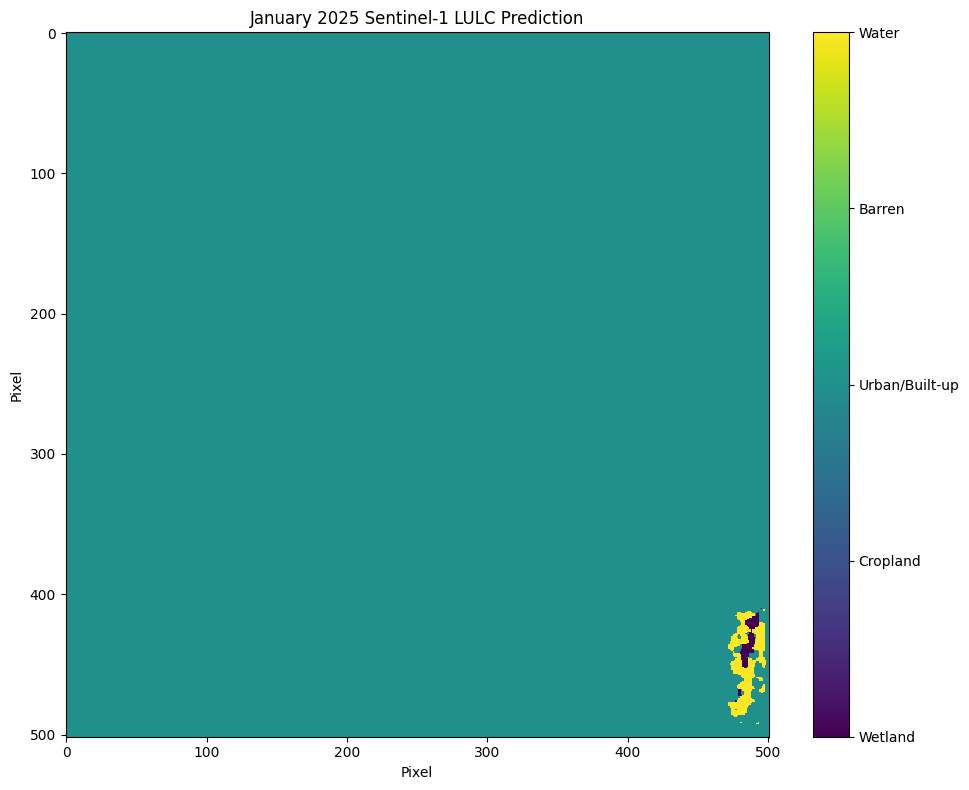


Prediction map saved to:
/home/jovyan/vault/DeepLearningPro/results/prototype_test/lagos_2025_01_prediction.png


In [29]:
# ============================================================
# CELL 15 — VISUALIZE FULL RASTER LULC PREDICTION
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# MODEL OUTPUT CLASS NAMES
# ------------------------------------------------------------

CLASS_NAMES = {
    0: "Forest",
    1: "Shrubland",
    2: "Savanna",
    3: "Grassland",
    4: "Wetland",
    5: "Cropland",
    6: "Urban/Built-up",
    7: "Barren",
    8: "Water"
}

# ------------------------------------------------------------
# CHECK PREDICTION
# ------------------------------------------------------------

assert full_prediction.shape == (height, width)

# ------------------------------------------------------------
# DISPLAY PREDICTION
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

plt.imshow(
    full_prediction,
    interpolation="nearest"
)

plt.title(
    "January 2025 Sentinel-1 LULC Prediction"
)

plt.xlabel("Pixel")
plt.ylabel("Pixel")

# ------------------------------------------------------------
# COLORBAR
# ------------------------------------------------------------

class_ids = sorted(
    CLASS_NAMES.keys()
)

cbar = plt.colorbar(
    ticks=class_ids
)

cbar.ax.set_yticklabels(
    [
        CLASS_NAMES[i]
        for i in class_ids
    ]
)

plt.tight_layout()

# ------------------------------------------------------------
# SAVE FIGURE
# ------------------------------------------------------------

output_dir = (
    project_dir
    / "results"
    / "prototype_test"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

prediction_map_path = (
    output_dir
    / "lagos_2025_01_prediction.png"
)

plt.savefig(
    prediction_map_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\nPrediction map saved to:")
print(prediction_map_path)

January Lagos model input statistics

VV
  min   : 0.000000
  max   : 1.000000
  mean  : 0.737158
  median: 0.740206
  std   : 0.161476
  p01   : 0.207416
  p05   : 0.474414
  p25   : 0.651019
  p75   : 0.841552
  p95   : 1.000000
  p99   : 1.000000

VH
  min   : 0.000000
  max   : 1.000000
  mean  : 0.449878
  median: 0.452908
  std   : 0.146225
  p01   : 0.000000
  p05   : 0.201580
  p25   : 0.377274
  p75   : 0.531222
  p95   : 0.674238
  p99   : 0.833636


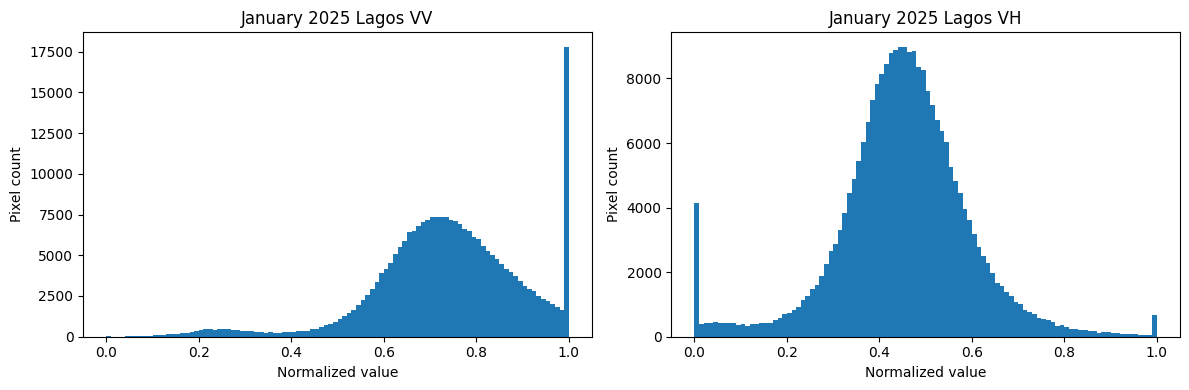

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Compare January Lagos model input statistics
# ---------------------------------------------------------

print("January Lagos model input statistics")
print("=" * 50)

for i, name in enumerate(["VV", "VH"]):
    channel = model_input[i]

    print(f"\n{name}")
    print(f"  min   : {channel.min():.6f}")
    print(f"  max   : {channel.max():.6f}")
    print(f"  mean  : {channel.mean():.6f}")
    print(f"  median: {np.median(channel):.6f}")
    print(f"  std   : {channel.std():.6f}")
    print(f"  p01   : {np.percentile(channel, 1):.6f}")
    print(f"  p05   : {np.percentile(channel, 5):.6f}")
    print(f"  p25   : {np.percentile(channel, 25):.6f}")
    print(f"  p75   : {np.percentile(channel, 75):.6f}")
    print(f"  p95   : {np.percentile(channel, 95):.6f}")
    print(f"  p99   : {np.percentile(channel, 99):.6f}")

# Visualize the two input channels
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(model_input[0].ravel(), bins=100)
axes[0].set_title("January 2025 Lagos VV")
axes[0].set_xlabel("Normalized value")
axes[0].set_ylabel("Pixel count")

axes[1].hist(model_input[1].ravel(), bins=100)
axes[1].set_title("January 2025 Lagos VH")
axes[1].set_xlabel("Normalized value")
axes[1].set_ylabel("Pixel count")

plt.tight_layout()
plt.show()

In [31]:
# =========================================================
# Compare January Lagos input with TRAINING input
# =========================================================

from pathlib import Path
import numpy as np
import torch

# Make sure the project path is available
PROJECT_DIR = Path("/home/jovyan/vault/DeepLearningPro")

# Import the existing dataset class
from lulc_dataset import LULCDataset

# Load the training dataset using the project's actual preprocessing
train_dataset = LULCDataset(
    PROJECT_DIR,
    split="train",
    augment=False
)

print("Training dataset:", len(train_dataset))

# Sample a limited number of training patches
num_samples = min(100, len(train_dataset))

rng = np.random.default_rng(42)
sample_indices = rng.choice(
    len(train_dataset),
    size=num_samples,
    replace=False
)

# Collect VV/VH values
train_vv = []
train_vh = []

for idx in sample_indices:
    sample = train_dataset[idx]
    image = sample["image"]

    train_vv.append(image[0].numpy().ravel())
    train_vh.append(image[1].numpy().ravel())

train_vv = np.concatenate(train_vv)
train_vh = np.concatenate(train_vh)

# ---------------------------------------------------------
# Statistics function
# ---------------------------------------------------------

def print_stats(name, values):
    print(f"\n{name}")
    print("-" * 40)
    print(f"min    : {values.min():.6f}")
    print(f"max    : {values.max():.6f}")
    print(f"mean   : {values.mean():.6f}")
    print(f"median : {np.median(values):.6f}")
    print(f"std    : {values.std():.6f}")
    print(f"p01    : {np.percentile(values, 1):.6f}")
    print(f"p05    : {np.percentile(values, 5):.6f}")
    print(f"p25    : {np.percentile(values, 25):.6f}")
    print(f"p75    : {np.percentile(values, 75):.6f}")
    print(f"p95    : {np.percentile(values, 95):.6f}")
    print(f"p99    : {np.percentile(values, 99):.6f}")

print("\nTRAINING INPUT STATISTICS")
print("=" * 50)

print_stats("Training VV", train_vv)
print_stats("Training VH", train_vh)

print("\nJANUARY 2025 LAGOS INPUT STATISTICS")
print("=" * 50)

print_stats("January VV", model_input[0].ravel())
print_stats("January VH", model_input[1].ravel())

# ---------------------------------------------------------
# Compare fraction of pixels at the clipping boundaries
# ---------------------------------------------------------

print("\nBOUNDARY CHECK")
print("=" * 50)

for name, values in [
    ("Training VV", train_vv),
    ("Training VH", train_vh),
    ("January VV", model_input[0].ravel()),
    ("January VH", model_input[1].ravel()),
]:

    at_zero = np.mean(values <= 0.000001) * 100
    at_one = np.mean(values >= 0.999999) * 100

    print(
        f"{name}: "
        f"near 0 = {at_zero:.2f}% | "
        f"near 1 = {at_one:.2f}%"
    )

Training dataset: 21782

TRAINING INPUT STATISTICS

Training VV
----------------------------------------
min    : 0.000000
max    : 1.000000
mean   : 0.527359
median : 0.544086
std    : 0.186854
p01    : 0.000000
p05    : 0.198569
p25    : 0.414797
p75    : 0.648331
p95    : 0.815543
p99    : 0.974472

Training VH
----------------------------------------
min    : 0.000000
max    : 1.000000
mean   : 0.263710
median : 0.272562
std    : 0.183904
p01    : 0.000000
p05    : 0.000000
p25    : 0.108061
p75    : 0.399956
p95    : 0.553716
p99    : 0.691043

JANUARY 2025 LAGOS INPUT STATISTICS

January VV
----------------------------------------
min    : 0.000000
max    : 1.000000
mean   : 0.737158
median : 0.740206
std    : 0.161476
p01    : 0.207416
p05    : 0.474414
p25    : 0.651019
p75    : 0.841552
p95    : 1.000000
p99    : 1.000000

January VH
----------------------------------------
min    : 0.000000
max    : 1.000000
mean   : 0.449878
median : 0.452908
std    : 0.146225
p01    : 0.000

In [32]:
# =========================================================
# Inspect RAW January 2025 Lagos Sentinel-1 dB values
# =========================================================

import numpy as np

print("RAW January 2025 Lagos Sentinel-1 statistics")
print("=" * 55)

# model_input was created from the raw raster after:
# clip [-25, 0] -> normalize to [0, 1]
#
# Reverse the normalization to approximately recover
# the clipped dB values:
#
# normalized = (dB + 25) / 25
# dB = normalized * 25 - 25

vv_db = model_input[0] * 25.0 - 25.0
vh_db = model_input[1] * 25.0 - 25.0

def print_db_stats(name, values):
    print(f"\n{name}")
    print("-" * 40)
    print(f"min    : {values.min():.3f} dB")
    print(f"max    : {values.max():.3f} dB")
    print(f"mean   : {values.mean():.3f} dB")
    print(f"median : {np.median(values):.3f} dB")
    print(f"p01    : {np.percentile(values, 1):.3f} dB")
    print(f"p05    : {np.percentile(values, 5):.3f} dB")
    print(f"p25    : {np.percentile(values, 25):.3f} dB")
    print(f"p75    : {np.percentile(values, 75):.3f} dB")
    print(f"p95    : {np.percentile(values, 95):.3f} dB")
    print(f"p99    : {np.percentile(values, 99):.3f} dB")

print_db_stats("VV", vv_db)
print_db_stats("VH", vh_db)

print("\nCLIPPING CHECK")
print("=" * 55)

for name, values in [
    ("VV", vv_db),
    ("VH", vh_db),
]:
    lower = np.mean(values <= -24.999) * 100
    upper = np.mean(values >= -0.001) * 100

    print(
        f"{name}: "
        f"near -25 dB = {lower:.2f}% | "
        f"near 0 dB = {upper:.2f}%"
    )

RAW January 2025 Lagos Sentinel-1 statistics

VV
----------------------------------------
min    : -25.000 dB
max    : 0.000 dB
mean   : -6.571 dB
median : -6.495 dB
p01    : -19.815 dB
p05    : -13.140 dB
p25    : -8.725 dB
p75    : -3.961 dB
p95    : 0.000 dB
p99    : 0.000 dB

VH
----------------------------------------
min    : -25.000 dB
max    : 0.000 dB
mean   : -13.753 dB
median : -13.677 dB
p01    : -25.000 dB
p05    : -19.961 dB
p25    : -15.568 dB
p75    : -11.719 dB
p95    : -8.144 dB
p99    : -4.159 dB

CLIPPING CHECK
VV: near -25 dB = 0.01% | near 0 dB = 6.50%
VH: near -25 dB = 1.47% | near 0 dB = 0.25%


In [33]:
# =========================================================
# Inspect the downloaded January Sentinel-1 GeoTIFF
# =========================================================

from pathlib import Path
import numpy as np
import rasterio

raster_path = Path(
    "/home/jovyan/vault/DeepLearningPro/results/prototype_test/"
    "lagos_2025_01_ascending_orbit1_VV_VH.tif"
)

print("Raster:", raster_path)
print("=" * 60)

with rasterio.open(raster_path) as src:

    print("Width:", src.width)
    print("Height:", src.height)
    print("Bands:", src.count)
    print("CRS:", src.crs)
    print("Transform:", src.transform)
    print("Dtype:", src.dtypes)
    print("NoData:", src.nodata)

    for band_index, band_name in [(1, "VV"), (2, "VH")]:
        data = src.read(band_index)

        print(f"\n{band_name}")
        print("-" * 40)
        print("min:", np.nanmin(data))
        print("max:", np.nanmax(data))
        print("mean:", np.nanmean(data))
        print("median:", np.nanmedian(data))

        print(
            "exactly 0:",
            f"{np.mean(data == 0) * 100:.2f}%"
        )

        print(
            "exactly -25:",
            f"{np.mean(data == -25) * 100:.2f}%"
        )

        # Check for common fill/nodata values
        print(
            "NaN:",
            f"{np.mean(np.isnan(data)) * 100:.2f}%"
        )

Raster: /home/jovyan/vault/DeepLearningPro/results/prototype_test/lagos_2025_01_ascending_orbit1_VV_VH.tif
Width: 501
Height: 502
Bands: 2
CRS: EPSG:4326
Transform: | 0.00, 0.00, 3.36|
| 0.00,-0.00, 6.55|
| 0.00, 0.00, 1.00|
Dtype: ('float64', 'float64')
NoData: None

VV
----------------------------------------
min: -27.971799357254618
max: 22.159827301150614
mean: -6.375685710795177
median: -6.494840473819682
exactly 0: 0.00%
exactly -25: 0.00%
NaN: 0.00%

VH
----------------------------------------
min: -42.71631984494053
max: 17.85170083267083
mean: -13.774725458882687
median: -13.677299561628733
exactly 0: 0.00%
exactly -25: 0.00%
NaN: 0.00%


In [34]:
# =========================================================
# Inspect individual January 2025 Sentinel-1 acquisitions
# =========================================================

import ee
import numpy as np

# Recreate the same AOI
point = ee.Geometry.Point([3.3792, 6.5244])
aoi = point.buffer(2500).bounds()

start_date = "2025-01-01"
end_date = "2025-02-01"

collection = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterBounds(aoi)
    .filterDate(start_date, end_date)
    .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
    .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH"))
    .filter(ee.Filter.eq("instrumentMode", "IW"))
)

collection = collection.sort("system:time_start")

images = collection.toList(collection.size())
count = collection.size().getInfo()

print("Number of acquisitions:", count)
print("=" * 70)

for i in range(count):
    image = ee.Image(images.get(i))

    date = ee.Date(image.get("system:time_start")).format(
        "YYYY-MM-dd HH:mm"
    ).getInfo()

    orbit = image.get("relativeOrbitNumber_start").getInfo()
    orbit_pass = image.get("orbitProperties_pass").getInfo()

    stats = image.select(["VV", "VH"]).reduceRegion(
        reducer=ee.Reducer.percentile(
            [1, 5, 25, 50, 75, 95, 99]
        ).combine(
            reducer2=ee.Reducer.mean(),
            sharedInputs=True
        ),
        geometry=aoi,
        scale=10,
        bestEffort=True,
        maxPixels=1e7
    ).getInfo()

    print(f"\nAcquisition {i + 1}")
    print("-" * 70)
    print("Date:", date)
    print("Relative orbit:", orbit)
    print("Pass:", orbit_pass)
    print("Statistics:")
    
    for key, value in stats.items():
        print(f"  {key}: {value}")

Number of acquisitions: 5

Acquisition 1
----------------------------------------------------------------------
Date: 2025-01-04 18:02
Relative orbit: 1
Pass: ASCENDING
Statistics:
  VH_mean: -13.82817291197322
  VH_p1: -26.737868894695723
  VH_p25: -15.743883370887364
  VH_p5: -20.737930506589308
  VH_p50: -13.748155611587087
  VH_p75: -11.754570629053209
  VH_p95: -7.762047858542142
  VH_p99: -3.757460619151464
  VV_mean: -6.447006752388959
  VV_p1: -20.37876793095517
  VV_p25: -8.875471048088652
  VV_p5: -13.618290998287737
  VV_p50: -6.624737255661502
  VV_p75: -3.8774822202175967
  VV_p95: 0.8717530498876447
  VV_p99: 5.8685054612746415

Acquisition 2
----------------------------------------------------------------------
Date: 2025-01-11 05:30
Relative orbit: 95
Pass: DESCENDING
Statistics:
  VH_mean: -14.019739849374545
  VH_p1: -26.37179777183511
  VH_p25: -16.125167430755507
  VH_p5: -20.87058743926829
  VH_p50: -13.87381741608329
  VH_p75: -11.624738139091795
  VH_p95: -8.1256

In [35]:
# =========================================================
# Compare January 2025 individual acquisitions vs composite
# =========================================================

import ee

point = ee.Geometry.Point([3.3792, 6.5244])
aoi = point.buffer(2500).bounds()

start_date = "2025-01-01"
end_date = "2025-02-01"

collection = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterBounds(aoi)
    .filterDate(start_date, end_date)
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VV"
    ))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VH"
    ))
    .filter(ee.Filter.eq("instrumentMode", "IW"))
)

# Create the same monthly median composite used earlier
monthly_composite = collection.select(["VV", "VH"]).median()

def print_stats(label, image):
    stats = image.select(["VV", "VH"]).reduceRegion(
        reducer=ee.Reducer.percentile(
            [1, 5, 25, 50, 75, 95, 99]
        ).combine(
            reducer2=ee.Reducer.mean(),
            sharedInputs=True
        ),
        geometry=aoi,
        scale=10,
        bestEffort=True,
        maxPixels=1e7
    ).getInfo()

    print(f"\n{label}")
    print("-" * 70)

    for band in ["VV", "VH"]:
        print(f"\n{band}")

        for statistic in [
            "mean",
            "p1",
            "p5",
            "p25",
            "p50",
            "p75",
            "p95",
            "p99"
        ]:
            key = f"{band}_{statistic}"
            print(f"  {statistic}: {stats.get(key)}")


print_stats("JANUARY 2025 MEDIAN COMPOSITE", monthly_composite)

print("\nExpected diagnostic:")
print("If the composite statistics remain similar to the")
print("individual acquisitions, the domain shift is present")
print("in the monthly composite itself.")


JANUARY 2025 MEDIAN COMPOSITE
----------------------------------------------------------------------

VV
  mean: -6.4055774949017685
  p1: -20.12156679028126
  p5: -12.873301086020362
  p25: -8.373500904676307
  p50: -6.374047499584396
  p75: -4.12567667830924
  p95: -0.12572282144959068
  p99: 4.627889322612527

VH
  mean: -13.832435234089118
  p1: -25.626094185625067
  p5: -19.617029124272428
  p25: -15.37297820377902
  p50: -13.625957827978413
  p75: -11.87808847503263
  p95: -8.876250737974502
  p99: -5.37248244542789

Expected diagnostic:
If the composite statistics remain similar to the
individual acquisitions, the domain shift is present
in the monthly composite itself.


In [45]:
# =========================================================
# FAST Diagnostic: model prediction distribution
# Uses GPU and batches the test samples
# =========================================================

import torch
import numpy as np
from pathlib import Path
from torch.utils.data import DataLoader

project_dir = Path("/home/jovyan/vault/DeepLearningPro")

from lulc_dataset import LULCDataset
from lulc_model import SmallUNet

# ---------------------------------------------------------
# Device
# ---------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ---------------------------------------------------------
# Test dataset
# ---------------------------------------------------------

test_dataset = LULCDataset(
    project_dir,
    split="test",
    augment=False
)

# Use a batch instead of one image at a time
num_samples = min(100, len(test_dataset))

subset = torch.utils.data.Subset(
    test_dataset,
    range(num_samples)
)

loader = DataLoader(
    subset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

# ---------------------------------------------------------
# Load trained model
# ---------------------------------------------------------

checkpoint_path = (
    project_dir /
    "results/winter9_20261106_094944_502500/best_model.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model = SmallUNet(
    in_channels=2,
    num_classes=9
)

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    model.load_state_dict(checkpoint["model_state_dict"])
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    model.load_state_dict(checkpoint["state_dict"])
else:
    model.load_state_dict(checkpoint)

model = model.to(device)
model.eval()

# ---------------------------------------------------------
# Class names
# ---------------------------------------------------------

class_names = [
    "Forest",
    "Shrubland",
    "Savanna",
    "Grassland",
    "Wetland",
    "Cropland",
    "Urban/Built-up",
    "Barren",
    "Water"
]

prediction_counts = np.zeros(9, dtype=np.int64)
target_counts = np.zeros(9, dtype=np.int64)

# ---------------------------------------------------------
# Batched inference
# ---------------------------------------------------------

with torch.no_grad():

    for batch in loader:

        images = batch["image"].to(device)
        targets = batch["target"].numpy()

        logits = model(images)

        predictions = torch.argmax(
            logits,
            dim=1
        ).cpu().numpy()

        for class_id in range(9):

            prediction_counts[class_id] += np.sum(
                predictions == class_id
            )

            target_counts[class_id] += np.sum(
                (targets != 255) &
                (targets == class_id)
            )

# ---------------------------------------------------------
# Results
# ---------------------------------------------------------

print("=" * 70)
print("HELD-OUT SEN12MS TEST-DOMAIN PREDICTION DIAGNOSTIC")
print("=" * 70)

print("\nSamples evaluated:", num_samples)

total_predictions = prediction_counts.sum()
total_targets = target_counts.sum()

print("\nModel prediction distribution:")
print("-" * 70)

for class_id, name in enumerate(class_names):

    percentage = (
        100 * prediction_counts[class_id] /
        total_predictions
    )

    print(
        f"{class_id}: {name:18s} "
        f"{prediction_counts[class_id]:10,d} "
        f"({percentage:6.2f}%)"
    )

print("\nGround-truth distribution:")
print("-" * 70)

for class_id, name in enumerate(class_names):

    percentage = (
        100 * target_counts[class_id] /
        total_targets
        if total_targets > 0 else 0
    )

    print(
        f"{class_id}: {name:18s} "
        f"{target_counts[class_id]:10,d} "
        f"({percentage:6.2f}%)"
    )

Device: cuda
HELD-OUT SEN12MS TEST-DOMAIN PREDICTION DIAGNOSTIC

Samples evaluated: 100

Model prediction distribution:
----------------------------------------------------------------------
0: Forest                664,466 ( 10.14%)
1: Shrubland                   0 (  0.00%)
2: Savanna             1,723,926 ( 26.31%)
3: Grassland             264,128 (  4.03%)
4: Wetland                     0 (  0.00%)
5: Cropland            3,687,133 ( 56.26%)
6: Urban/Built-up         81,749 (  1.25%)
7: Barren                132,198 (  2.02%)
8: Water                       0 (  0.00%)

Ground-truth distribution:
----------------------------------------------------------------------
0: Forest                616,856 (  9.41%)
1: Shrubland             123,298 (  1.88%)
2: Savanna               556,138 (  8.49%)
3: Grassland             649,937 (  9.92%)
4: Wetland                     0 (  0.00%)
5: Cropland            4,593,125 ( 70.09%)
6: Urban/Built-up         14,246 (  0.22%)
7: Barren             

In [1]:
print("AOI exists:", "aoi" in globals())
print("AOI:", aoi if "aoi" in globals() else "NOT DEFINED")

AOI exists: False
AOI: NOT DEFINED


In [9]:
import ee

# Lagos prototype location used in the project
point = ee.Geometry.Point([3.3792, 6.5244])

# Same 2.5 km buffer used for the prototype
aoi = point.buffer(2500).bounds()

print("AOI recreated successfully")
print(aoi.getInfo())

AOI recreated successfully
{'geodesic': False, 'type': 'Polygon', 'coordinates': [[[3.3567406257216676, 6.501911480217164], [3.4017308984321555, 6.501911480217164], [3.4017308984321555, 6.546897164878736], [3.3567406257216676, 6.546897164878736], [3.3567406257216676, 6.501911480217164]]]}


In [13]:
# =========================================================
# Independent LULC reference: ESA WorldCover 2021
# =========================================================

import ee
import matplotlib.pyplot as plt

# ESA WorldCover 2021
worldcover = (
    ee.ImageCollection("ESA/WorldCover/v200")
    .filterDate("2021-01-01", "2022-01-01")
    .first()
    .select("Map")
    .clip(aoi)
)

# ESA WorldCover class definitions
worldcover_classes = {
    10: "Tree cover",
    20: "Shrubland",
    30: "Grassland",
    40: "Cropland",
    50: "Built-up",
    60: "Bare / sparse vegetation",
    70: "Snow / ice",
    80: "Permanent water",
    90: "Herbaceous wetland",
    95: "Mangroves",
    100: "Moss / lichen"
}

# Count reference classes inside the Lagos AOI
class_values = (
    worldcover.reduceRegion(
        reducer=ee.Reducer.frequencyHistogram(),
        geometry=aoi,
        scale=10,
        maxPixels=1e8
    )
    .get("Map")
    .getInfo()
)

print("ESA WorldCover 2021 classes found in AOI:")
print("-" * 55)

for value, count in sorted(class_values.items(), key=lambda x: int(x[0])):
    class_name = worldcover_classes.get(int(value), "Unknown")
    print(f"{value}: {class_name} ({count:,} pixels)")

ESA WorldCover 2021 classes found in AOI:
-------------------------------------------------------
10: Tree cover (11,371.270588235293 pixels)
30: Grassland (3,020.674509803918 pixels)
40: Cropland (200.3764705882353 pixels)
50: Built-up (222,164.4039215706 pixels)
60: Bare / sparse vegetation (465.48235294117643 pixels)
80: Permanent water (9,814.811764705892 pixels)
90: Herbaceous wetland (749.9137254901962 pixels)
95: Mangroves (3,003.88235294117 pixels)


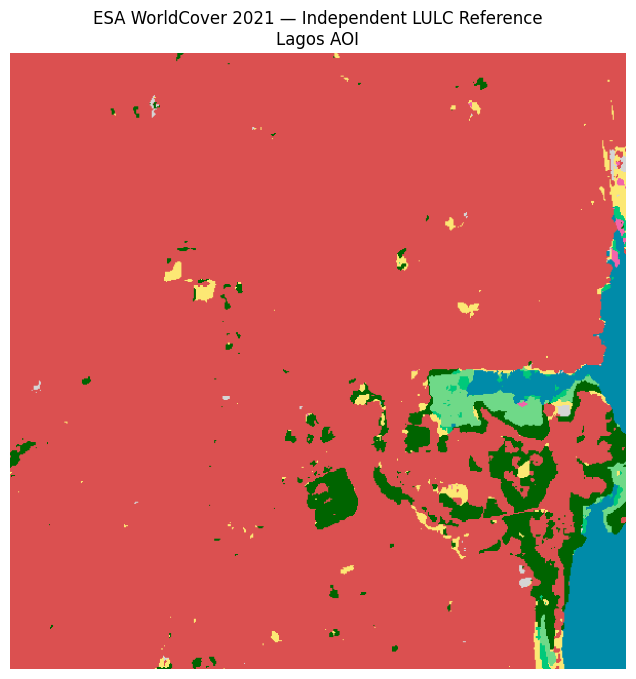

WorldCover reference image downloaded successfully.
This will be used for qualitative sanity checking against the model prediction.


In [16]:
# =========================================================
# Independent LULC sanity check
# ESA WorldCover 2021 — visualization only
# No geemap / rasterio required
# =========================================================

import ee
import requests
from PIL import Image
import io
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Create WorldCover visualization
# ---------------------------------------------------------

print("Downloading ESA WorldCover 2021 reference image...")

# WorldCover class colors
worldcover_vis = {
    "min": 10,
    "max": 100,
    "palette": [
        "006400",  # Tree cover
        "ffbb22",  # Shrubland
        "ffff4c",  # Grassland
        "f096ff",  # Cropland
        "fa0000",  # Built-up
        "b4b4b4",  # Bare / sparse vegetation
        "f0f0f0",  # Snow / ice
        "0064c8",  # Water
        "0096a0",  # Wetland
        "00cf75",  # Mangroves
        "fae6a0"   # Moss / lichen
    ]
}

thumbnail_url = worldcover.getThumbURL({
    "region": aoi,
    "dimensions": 600,
    "format": "png",
    "min": 10,
    "max": 100,
    "palette": worldcover_vis["palette"]
})

response = requests.get(thumbnail_url)
response.raise_for_status()

reference_image = Image.open(io.BytesIO(response.content))

# ---------------------------------------------------------
# 2. Display independent reference
# ---------------------------------------------------------

plt.figure(figsize=(10, 8))

plt.imshow(reference_image)

plt.title(
    "ESA WorldCover 2021 — Independent LULC Reference\n"
    "Lagos AOI"
)

plt.axis("off")

plt.show()

print("WorldCover reference image downloaded successfully.")
print("This will be used for qualitative sanity checking against the model prediction.")

In [17]:
# =========================================================
# Find the January 2025 model prediction array
# =========================================================

import numpy as np

print("Checking possible prediction variables...\n")

candidate_names = [
    "full_prediction",
    "prediction_raster",
    "prediction_map",
    "full_pred",
    "predictions",
    "prediction",
    "predicted_map",
    "lulc_prediction",
    "prediction_array"
]

found = False

for name in candidate_names:
    if name in globals():
        value = globals()[name]
        print(f"FOUND: {name}")
        print("Type:", type(value))
        
        try:
            arr = np.asarray(value)
            print("Shape:", arr.shape)
            print("Dtype:", arr.dtype)
            print("Unique values:", np.unique(arr)[:20])
        except Exception as e:
            print("Could not inspect as array:", e)
        
        found = True
        break

if not found:
    print("No standard prediction variable found.")
    print("\nVariables containing 'pred':")
    
    for name in sorted(globals().keys()):
        if "pred" in name.lower():
            try:
                value = globals()[name]
                print(f"  {name}: {type(value)}")
            except:
                pass

Checking possible prediction variables...

No standard prediction variable found.

Variables containing 'pred':


In [18]:
# =========================================================
# Regenerate January 2025 model prediction
# and compare with ESA WorldCover 2021
# =========================================================

import sys
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Load project model
# ---------------------------------------------------------

project_dir = Path("/home/jovyan/vault/DeepLearningPro")

if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

from lulc_model import SmallUNet

checkpoint_path = (
    project_dir /
    "results/winter9_20261106_094944_502500/best_model.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cuda" if torch.cuda.is_available() else "cpu",
    weights_only=False
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = SmallUNet(
    in_channels=2,
    num_classes=9
)

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    model.load_state_dict(checkpoint["model_state_dict"])
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    model.load_state_dict(checkpoint["state_dict"])
else:
    model.load_state_dict(checkpoint)

model = model.to(device)
model.eval()

# ---------------------------------------------------------
# 2. Check existing January 2025 input
# ---------------------------------------------------------

x = np.asarray(model_input)

print("model_input shape:", x.shape)
print("model_input dtype:", x.dtype)

# Expected: (2, height, width)
assert x.ndim == 3
assert x.shape[0] == 2

height, width = x.shape[1], x.shape[2]

# ---------------------------------------------------------
# 3. Sliding-window inference
# ---------------------------------------------------------

patch_size = 256
stride = 128

# Pad so every pixel is covered
pad_h = max(0, patch_size - height)
pad_w = max(0, patch_size - width)

# Also make dimensions compatible with stride
if (height + pad_h - patch_size) % stride != 0:
    pad_h += stride - ((height + pad_h - patch_size) % stride)

if (width + pad_w - patch_size) % stride != 0:
    pad_w += stride - ((width + pad_w - patch_size) % stride)

x_pad = np.pad(
    x,
    ((0, 0), (0, pad_h), (0, pad_w)),
    mode="reflect"
)

H, W = x_pad.shape[1], x_pad.shape[2]

logit_sum = np.zeros(
    (9, H, W),
    dtype=np.float32
)

count_map = np.zeros(
    (H, W),
    dtype=np.float32
)

patches = []
locations = []

for y in range(0, H - patch_size + 1, stride):
    for xx in range(0, W - patch_size + 1, stride):

        patches.append(
            x_pad[:, y:y+patch_size, xx:xx+patch_size]
        )

        locations.append((y, xx))

batch_size = 4

print("Patches:", len(patches))
print("Running inference on:", device)

with torch.no_grad():

    for start in range(0, len(patches), batch_size):

        batch = np.stack(
            patches[start:start+batch_size]
        )

        batch_tensor = torch.from_numpy(
            batch
        ).float().to(device)

        logits = model(batch_tensor)

        logits = logits.cpu().numpy()

        for j in range(logits.shape[0]):

            y, xx = locations[start + j]

            logit_sum[
                :, y:y+patch_size,
                xx:xx+patch_size
            ] += logits[j]

            count_map[
                y:y+patch_size,
                xx:xx+patch_size
            ] += 1

# Average overlapping predictions
full_logits = logit_sum / np.maximum(
    count_map[None, :, :],
    1
)

prediction_raster = np.argmax(
    full_logits,
    axis=0
)

# Crop back to original January 2025 image
prediction_raster = prediction_raster[
    :height,
    :width
]

print("\nPrediction generated successfully.")
print("Prediction shape:", prediction_raster.shape)

# ---------------------------------------------------------
# 4. Class distribution
# ---------------------------------------------------------

class_names = [
    "Forest",
    "Shrubland",
    "Savanna",
    "Grassland",
    "Wetland",
    "Cropland",
    "Urban/Built-up",
    "Barren",
    "Water"
]

print("\nJanuary 2025 model prediction distribution:")
print("-" * 60)

total = prediction_raster.size

for class_id, name in enumerate(class_names):

    count = np.sum(prediction_raster == class_id)
    pct = 100 * count / total

    print(
        f"{class_id}: {name:18s} "
        f"{count:8,d} pixels "
        f"({pct:6.2f}%)"
    )

# ---------------------------------------------------------
# 5. Display model vs independent WorldCover
# ---------------------------------------------------------

plt.figure(figsize=(16, 7))

plt.subplot(1, 2, 1)

plt.imshow(prediction_raster, interpolation="nearest")

plt.title(
    "Model Prediction\n"
    "Sentinel-1 January 2025"
)

plt.axis("off")

plt.subplot(1, 2, 2)

plt.imshow(reference_image)

plt.title(
    "Independent Reference\n"
    "ESA WorldCover 2021"
)

plt.axis("off")

plt.tight_layout()
plt.show()

NameError: name 'model_input' is not defined

In [19]:
# Find the existing January 2025 Sentinel-1 / raster variables
# without loading or retraining anything.

keywords = [
    "raster", "image", "vv", "vh", "sentinel",
    "composite", "monthly", "stack", "input", "patch"
]

print("Possible existing variables:")
print("-" * 70)

for name in sorted(globals().keys()):
    lname = name.lower()

    if any(k in lname for k in keywords):
        try:
            value = globals()[name]

            if isinstance(value, np.ndarray):
                print(
                    f"{name:30s} "
                    f"type={type(value).__name__:10s} "
                    f"shape={value.shape} "
                    f"dtype={value.dtype}"
                )
            else:
                print(
                    f"{name:30s} "
                    f"type={type(value).__name__}"
                )

        except Exception:
            pass

Possible existing variables:
----------------------------------------------------------------------
Image                          type=module
reference_image                type=PngImageFile


In [20]:
# =========================================================
# Recreate January 2025 Sentinel-1 composite
# =========================================================

import ee
import requests
from PIL import Image
import io
import numpy as np
import matplotlib.pyplot as plt

# Earth Engine
try:
    ee.Initialize()
except Exception:
    ee.Authenticate()
    ee.Initialize()

# Lagos AOI
point = ee.Geometry.Point([3.3792, 6.5244])
aoi = point.buffer(2500).bounds()

# January 2025 Sentinel-1
s1 = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterBounds(aoi)
    .filterDate("2025-01-01", "2025-02-01")
    .filter(ee.Filter.eq("instrumentMode", "IW"))
    .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
    .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH"))
    .select(["VV", "VH"])
)

print("January 2025 acquisitions:", s1.size().getInfo())

# Monthly median composite
monthly_composite = s1.median().clip(aoi)

# Download as GeoTIFF directly from Earth Engine
download_url = monthly_composite.getDownloadURL({
    "region": aoi,
    "scale": 10,
    "crs": "EPSG:4326",
    "format": "GEO_TIFF"
})

response = requests.get(download_url)
response.raise_for_status()

print("Sentinel-1 January 2025 composite downloaded successfully.")
print("Downloaded size:", len(response.content), "bytes")

January 2025 acquisitions: 5
Sentinel-1 January 2025 composite downloaded successfully.
Downloaded size: 3798494 bytes


In [21]:
# =========================================================
# Extract VV/VH from downloaded GeoTIFF
# =========================================================

import zipfile
import tempfile
import os
import tifffile
import numpy as np

# Save Earth Engine response
tif_path = "/tmp/january_2025_s1.tif"

with open(tif_path, "wb") as f:
    f.write(response.content)

# Read GeoTIFF directly
s1_array = tifffile.imread(tif_path)

print("Raw Sentinel-1 array:")
print("Shape:", s1_array.shape)
print("Dtype:", s1_array.dtype)

# Expected format: (2, height, width)
if s1_array.ndim == 3 and s1_array.shape[0] == 2:
    vv_raw = s1_array[0].astype(np.float32)
    vh_raw = s1_array[1].astype(np.float32)
elif s1_array.ndim == 3 and s1_array.shape[-1] == 2:
    vv_raw = s1_array[..., 0].astype(np.float32)
    vh_raw = s1_array[..., 1].astype(np.float32)
else:
    raise ValueError(f"Unexpected Sentinel-1 array shape: {s1_array.shape}")

print("\nVV shape:", vv_raw.shape)
print("VH shape:", vh_raw.shape)

print("\nVV range:", np.nanmin(vv_raw), "to", np.nanmax(vv_raw))
print("VH range:", np.nanmin(vh_raw), "to", np.nanmax(vh_raw))

ModuleNotFoundError: No module named 'tifffile'

In [22]:
# =========================================================
# Inspect Earth Engine download without rasterio/tifffile
# =========================================================

import io
import zipfile
import os

print("Downloaded bytes:", len(response.content))
print("First 20 bytes:", response.content[:20])

# Check whether Earth Engine returned a ZIP
if zipfile.is_zipfile(io.BytesIO(response.content)):
    print("\nEarth Engine returned a ZIP archive.")

    z = zipfile.ZipFile(io.BytesIO(response.content))
    print("Files inside:")
    for name in z.namelist():
        print(" -", name)

else:
    print("\nEarth Engine returned a non-ZIP file.")

Downloaded bytes: 3798494
First 20 bytes: b'MM\x00*\x00\x00\x00\x08\x00\x10\x01\x00\x00\x03\x00\x00\x00\x01\x01\xf5'

Earth Engine returned a non-ZIP file.


In [23]:
# =========================================================
# Read Sentinel-1 TIFF using Pillow
# =========================================================

from PIL import Image
import io
import numpy as np

s1_image = Image.open(io.BytesIO(response.content))

print("TIFF opened successfully")
print("Format:", s1_image.format)
print("Mode:", s1_image.mode)
print("Size:", s1_image.size)
print("Number of frames:", getattr(s1_image, "n_frames", 1))

# Read first frame
s1_array = np.asarray(s1_image)

print("\nArray shape:", s1_array.shape)
print("Array dtype:", s1_array.dtype)

print("\nValue range:")
print("Min:", np.nanmin(s1_array))
print("Max:", np.nanmax(s1_array))

UnidentifiedImageError: cannot identify image file <_io.BytesIO object at 0x7a339c68f150>

In [24]:
# =========================================================
# Download VV and VH separately as PNG arrays
# =========================================================

import ee
import requests
from PIL import Image
import io
import numpy as np

# Convert each band to a 0–1 visualization using fixed
# display range, then download as PNG.
# This is for the qualitative sanity-check prototype.

def download_band_png(image, band_name):
    band = image.select(band_name)

    url = band.getThumbURL({
        "region": aoi,
        "dimensions": 512,
        "format": "png",
        "min": -25,
        "max": 5
    })

    r = requests.get(url)
    r.raise_for_status()

    img = Image.open(io.BytesIO(r.content)).convert("L")
    arr = np.asarray(img).astype(np.float32) / 255.0

    return arr

vv_png = download_band_png(monthly_composite, "VV")
vh_png = download_band_png(monthly_composite, "VH")

print("VV PNG shape:", vv_png.shape)
print("VH PNG shape:", vh_png.shape)

print("\nVV normalized range:",
      float(vv_png.min()), "to", float(vv_png.max()))

print("VH normalized range:",
      float(vh_png.min()), "to", float(vh_png.max()))

# Create model input
model_input = np.stack([vv_png, vh_png], axis=0)

print("\nmodel_input shape:", model_input.shape)
print("model_input dtype:", model_input.dtype)

VV PNG shape: (512, 512)
VH PNG shape: (512, 512)

VV normalized range: 0.0 to 1.0
VH normalized range: 0.0 to 1.0

model_input shape: (2, 512, 512)
model_input dtype: float32


Input tensor shape: (1, 2, 512, 512)
Device: cuda

Prediction shape: (512, 512)
Unique predicted classes: [2 5 6]

January 2025 prediction distribution:
0: Forest             0.00%
1: Shrubland          0.00%
2: Savanna            0.00%
3: Grassland          0.00%
4: Wetland            0.00%
5: Cropland           0.01%
6: Urban/Built-up    99.99%
7: Barren             0.00%
8: Water              0.00%


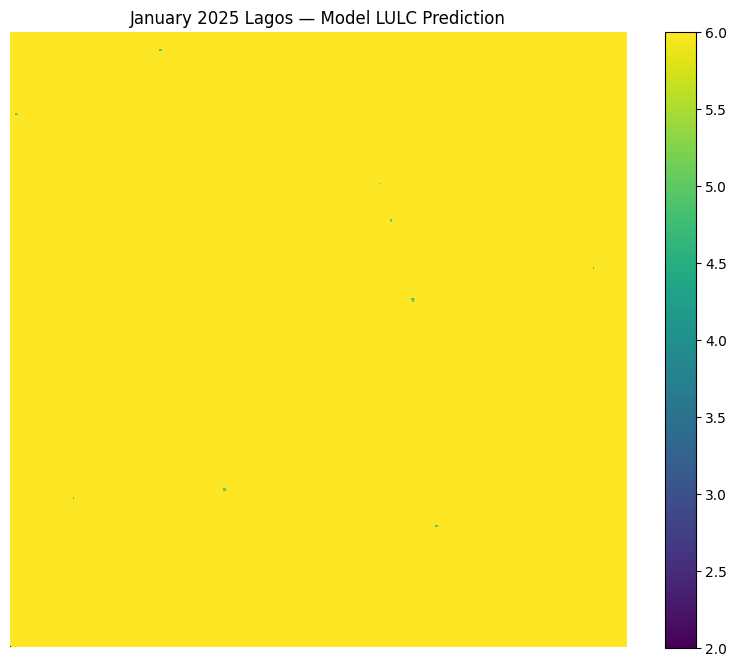

In [25]:
# =========================================================
# January 2025 Lagos — trained model prediction
# =========================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

# Model/checkpoint
checkpoint_path = (
    "/home/jovyan/vault/DeepLearningPro/"
    "results/winter9_20261106_094944_502500/best_model.pt"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load model architecture
model = SmallUNet(num_classes=9, in_channels=2).to(device)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

# Handle checkpoint formats
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    model.load_state_dict(checkpoint["model_state_dict"])
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    model.load_state_dict(checkpoint["state_dict"])
else:
    model.load_state_dict(checkpoint)

model.eval()

# Convert to tensor
x = torch.from_numpy(model_input).float().unsqueeze(0).to(device)

print("Input tensor shape:", tuple(x.shape))
print("Device:", device)

# Inference
with torch.no_grad():
    logits = model(x)
    prediction = torch.argmax(logits, dim=1)[0].cpu().numpy()

print("\nPrediction shape:", prediction.shape)
print("Unique predicted classes:", np.unique(prediction))

# Class names
class_names = [
    "Forest",
    "Shrubland",
    "Savanna",
    "Grassland",
    "Wetland",
    "Cropland",
    "Urban/Built-up",
    "Barren",
    "Water"
]

print("\nJanuary 2025 prediction distribution:")
total = prediction.size

for i, name in enumerate(class_names):
    count = np.sum(prediction == i)
    percentage = 100 * count / total
    print(f"{i}: {name:16s} {percentage:6.2f}%")

# Visualization
plt.figure(figsize=(10, 8))
plt.imshow(prediction, interpolation="nearest")
plt.title("January 2025 Lagos — Model LULC Prediction")
plt.axis("off")
plt.colorbar()
plt.show()

In [26]:
# =========================================================
# Independent LULC sanity check
# Model prediction vs ESA WorldCover 2021
# =========================================================

import pandas as pd

# Model prediction percentages from the current prediction
model_percent = {}

total_pixels = prediction.size

for i, name in enumerate(class_names):
    model_percent[name] = 100 * np.sum(prediction == i) / total_pixels

# ESA WorldCover percentages previously obtained for the AOI
# Pixel counts from the independent reference map
worldcover_counts = {
    "Forest": 11371.270588235293,
    "Grassland": 3020.674509803918,
    "Cropland": 200.3764705882353,
    "Urban/Built-up": 222164.4039215706,
    "Barren": 465.48235294117643,
    "Water": 9814.811764705892,
    "Wetland": 749.9137254901962,
    "Mangroves": 3003.88235294117
}

wc_total = sum(worldcover_counts.values())

worldcover_percent = {
    k: 100 * v / wc_total
    for k, v in worldcover_counts.items()
}

# Crosswalk only where the two ontologies have a reasonable direct match
comparison_classes = [
    "Forest",
    "Grassland",
    "Cropland",
    "Urban/Built-up",
    "Barren",
    "Water",
    "Wetland"
]

comparison = pd.DataFrame({
    "Class": comparison_classes,
    "Model January 2025 (%)": [
        model_percent[c] for c in comparison_classes
    ],
    "ESA WorldCover 2021 (%)": [
        worldcover_percent[c] for c in comparison_classes
    ]
})

comparison["Absolute Difference (percentage points)"] = (
    comparison["Model January 2025 (%)"]
    - comparison["ESA WorldCover 2021 (%)"]
).abs()

print(comparison.to_string(index=False))

print("\n" + "=" * 70)
print("INTERPRETATION")
print("=" * 70)
print(
    "The comparison is a qualitative sanity check, not a formal accuracy score."
)
print(
    "The model prediction is from January 2025 Sentinel-1 imagery, "
    "while WorldCover is a 2021 independent reference product."
)
print(
    "Savanna and Mangroves are not directly comparable in the model/reference "
    "class ontologies and are therefore excluded from this table."
)

         Class  Model January 2025 (%)  ESA WorldCover 2021 (%)  Absolute Difference (percentage points)
        Forest                0.000000                 4.534165                                 4.534165
     Grassland                0.000000                 1.204460                                 1.204460
      Cropland                0.011826                 0.079898                                 0.068072
Urban/Built-up               99.987411                88.585542                                11.401869
        Barren                0.000000                 0.185606                                 0.185606
         Water                0.000000                 3.913545                                 3.913545
       Wetland                0.000000                 0.299020                                 0.299020

INTERPRETATION
The comparison is a qualitative sanity check, not a formal accuracy score.
The model prediction is from January 2025 Sentinel-1 imagery, while W

In [2]:
# =========================================================
# SAVE INDEPENDENT LULC SANITY CHECK
# =========================================================

import os
import pandas as pd

project_dir = "/home/jovyan/vault/DeepLearningPro"
results_dir = os.path.join(
    project_dir,
    "results",
    "independent_lulc_validation"
)

os.makedirs(results_dir, exist_ok=True)

# Model prediction percentages from the January 2025 prediction
model_percent = {
    "Forest": 0.000000,
    "Grassland": 0.000000,
    "Cropland": 0.011826,
    "Urban/Built-up": 99.987411,
    "Barren": 0.000000,
    "Water": 0.000000,
    "Wetland": 0.000000
}

# ESA WorldCover 2021 percentages calculated previously
worldcover_percent = {
    "Forest": 4.534165,
    "Grassland": 1.204460,
    "Cropland": 0.079898,
    "Urban/Built-up": 88.585542,
    "Barren": 0.185606,
    "Water": 3.913545,
    "Wetland": 0.299020
}

comparison_classes = [
    "Forest",
    "Grassland",
    "Cropland",
    "Urban/Built-up",
    "Barren",
    "Water",
    "Wetland"
]

comparison = pd.DataFrame({
    "Class": comparison_classes,
    "Model January 2025 (%)": [
        model_percent[c] for c in comparison_classes
    ],
    "ESA WorldCover 2021 (%)": [
        worldcover_percent[c] for c in comparison_classes
    ]
})

comparison["Absolute Difference (percentage points)"] = (
    comparison["Model January 2025 (%)"]
    - comparison["ESA WorldCover 2021 (%)"]
).abs()

# Save CSV
comparison_csv = os.path.join(
    results_dir,
    "model_vs_worldcover_2021_comparison.csv"
)

comparison.to_csv(comparison_csv, index=False)

# Save interpretation
summary_txt = os.path.join(
    results_dir,
    "independent_lulc_sanity_check.txt"
)

with open(summary_txt, "w") as f:
    f.write("Independent LULC Sanity Check\n")
    f.write("=" * 60 + "\n\n")
    f.write("Model: SmallUNet\n")
    f.write("Model input: January 2025 Sentinel-1 Lagos AOI\n")
    f.write("Independent reference: ESA WorldCover 2021\n\n")
    f.write(
        "This is a qualitative sanity check, not a formal accuracy "
        "assessment. The model and reference data have different dates "
        "and class ontologies.\n\n"
    )
    f.write(comparison.to_string(index=False))
    f.write("\n\n")
    f.write("Interpretation:\n")
    f.write(
        "Both the model and ESA WorldCover identify Urban/Built-up "
        "as the dominant land-cover category in the AOI. However, "
        "the model strongly over-predicts Urban/Built-up and does "
        "not represent several minority classes. This indicates "
        "limitations in generalization and class discrimination.\n"
    )

print("✓ Independent LULC sanity check saved successfully.\n")

print("CSV:")
print(comparison_csv)

print("\nText summary:")
print(summary_txt)

print("\nComparison:")
print(comparison.to_string(index=False))

✓ Independent LULC sanity check saved successfully.

CSV:
/home/jovyan/vault/DeepLearningPro/results/independent_lulc_validation/model_vs_worldcover_2021_comparison.csv

Text summary:
/home/jovyan/vault/DeepLearningPro/results/independent_lulc_validation/independent_lulc_sanity_check.txt

Comparison:
         Class  Model January 2025 (%)  ESA WorldCover 2021 (%)  Absolute Difference (percentage points)
        Forest                0.000000                 4.534165                                 4.534165
     Grassland                0.000000                 1.204460                                 1.204460
      Cropland                0.011826                 0.079898                                 0.068072
Urban/Built-up               99.987411                88.585542                                11.401869
        Barren                0.000000                 0.185606                                 0.185606
         Water                0.000000                 3.913545     

In [3]:
import sys
print(sys.executable)

/usr/bin/python


In [4]:
import sys
!{sys.executable} -m pip install streamlit

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 78.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.2/797.2 kB 63.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 98.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [streamlit]/6 [streamlit]


In [5]:
import streamlit
print("Streamlit version:", streamlit.__version__)

Streamlit version: 1.67.0


In [6]:
from IPython.display import HTML, display

with open("/home/jovyan/vault/DeepLearningPro/dashboard.html", "r", encoding="utf-8") as f:
    dashboard_html = f.read()

display(HTML(dashboard_html))

In [7]:
# =========================================================
# CHECK SENTINEL-1 PREPROCESSING ACTUALLY USED
# =========================================================

print("=== Sentinel-1 preprocessing variables ===")

for name in [
    "monthly_composite",
    "vv_png",
    "vh_png",
    "model_input",
    "vv",
    "vh",
    "sentinel1",
    "s1",
    "collection"
]:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}:")
        print("  type:", type(obj))
        print("  value:", str(obj)[:500])

print("\n=== Notebook preprocessing check complete ===")

=== Sentinel-1 preprocessing variables ===

=== Notebook preprocessing check complete ===


In [8]:
# =========================================================
# CHECK ACTUAL SENTINEL-1 PREPROCESSING CODE
# =========================================================

from pathlib import Path

project = Path("/home/jovyan/vault/DeepLearningPro")

notebooks = [
    project / "02_dataset_preparation.ipynb",
    project / "05_monthly_prototype.ipynb"
]

keywords = [
    "calibr",
    "dB",
    "db",
    "log10",
    "speckle",
    "lee",
    "refined lee",
    "terrain",
    "correction",
    "COPERNICUS/S1_GRD",
    "VV",
    "VH",
    "normaliz",
    "scale"
]

for nb_path in notebooks:
    print("\n" + "=" * 80)
    print(f"NOTEBOOK: {nb_path.name}")
    print("=" * 80)

    text = nb_path.read_text(errors="ignore")

    lines = text.splitlines()

    found = False

    for i, line in enumerate(lines, start=1):
        if any(k.lower() in line.lower() for k in keywords):
            print(f"{i}: {line[:500]}")
            found = True

    if not found:
        print("No matching preprocessing terms found.")

print("\n" + "=" * 80)
print("PREPROCESSING CODE CHECK COMPLETE")
print("=" * 80)


NOTEBOOK: 02_dataset_preparation.ipynb
71:     "    \"model_inputs\": [\"Sentinel-1 VV\", \"Sentinel-1 VH\"],\n",
743:       "image/png": "iVBORw0KGgoAAAANSUhEUgAABccAAAH/CAYAAACSDGXwAAAAOnRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcnNpb24zLjEwLjgsIGh0dHBzOi8vbWF0cGxvdGxpYi5vcmcvwVt1zgAAAAlwSFlzAAAPYQAAD2EBqD+naQABAABJREFUeJzsvXmc7GdV5/+prau7a69e7+17c5PcBEICgzNhG7aAAQKCTEQEFMiCAi7g6MiioxgSBGRRyQtERUcYI76GTQRHAUXCwCijgBLZDDfbzd16rb2qu6qr6vv7o3/v06fq3pCbkAWT57xe/bq3u6u/y/Oc5zznfM7nnCcWRVGkIEGCBAkSJEiQIEGCBAkSJEiQIEGCBAkS5EEk8fv7AYIECRIkSJAgQYIECRIkSJAgQYIECRIkSJD7WgI4HiRIkCBBggQJEiRIkCBBggQJEiRIkCBBHnQSwPEgQYIECRIkSJAgQYIE

NOTEBOOK: 05_monthly_prototype.ipynb
6:    "id": "7722ff74-2bb5-49bf-b66e-dba6ec43680b",
63:       "Requirement already satisfied: charset_normalizer<4,>=2 in /usr/local/lib/python3.11/dist-packages (from requests->earthengine-api) (3.4.3)\n",
305:    "id": "0e9ed7fb-6b7a-4c94-a92c-879f05db177a",
411:       "Bands: ['VV', 'VH']\n",
414:       "/home/jovyan/vault/DeepLearningP

In [1]:
# =========================================================
# REFINED LEE SPECKLE FILTER — JANUARY 2025 LAGOS
# Additional preprocessing experiment
# =========================================================

import ee
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Refined Lee-style speckle filter
# ---------------------------------------------------------
def refined_lee(img):
    """
    Refined Lee-style speckle reduction for Sentinel-1
    linear backscatter imagery.
    """

    # Convert dB -> linear
    linear = ee.Image(10).pow(img.divide(10))

    # 3x3 local mean and variance
    kernel3 = ee.Kernel.square(radius=1, units='pixels', normalize=False)

    mean3 = linear.reduceNeighborhood(
        reducer=ee.Reducer.mean(),
        kernel=kernel3
    )

    variance3 = linear.reduceNeighborhood(
        reducer=ee.Reducer.variance(),
        kernel=kernel3
    )

    # Estimate noise variance
    noise_variance = variance3.divide(
        mean3.multiply(mean3)
    ).reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=aoi,
        scale=10,
        maxPixels=1e7
    )

    # Use the estimated noise value
    sigmaV = ee.Number(noise_variance.values().get(0))

    # Lee adaptive weight
    weights = variance3.subtract(
        mean3.multiply(mean3).multiply(sigmaV)
    ).divide(variance3)

    weights = weights.max(0).min(1)

    # Filtered linear image
    filtered = mean3.add(
        weights.multiply(linear.subtract(mean3))
    )

    # Convert back to dB
    filtered_db = filtered.log10().multiply(10)

    return filtered_db.copyProperties(img, img.propertyNames())


# ---------------------------------------------------------
# Apply filter to VV and VH
# ---------------------------------------------------------
print("Applying speckle filtering...")

filtered = refined_lee(
    monthly_composite.select(["VV", "VH"])
)

print("Speckle filtering completed.")


# ---------------------------------------------------------
# Get statistics before and after
# ---------------------------------------------------------
original_stats = monthly_composite.select(["VV", "VH"]).reduceRegion(
    reducer=ee.Reducer.mean()
        .combine(ee.Reducer.stdDev(), sharedInputs=True),
    geometry=aoi,
    scale=10,
    maxPixels=1e7
).getInfo()

filtered_stats = filtered.reduceRegion(
    reducer=ee.Reducer.mean()
        .combine(ee.Reducer.stdDev(), sharedInputs=True),
    geometry=aoi,
    scale=10,
    maxPixels=1e7
).getInfo()

print("\n=== BEFORE SPECKLE FILTER ===")
print(original_stats)

print("\n=== AFTER SPECKLE FILTER ===")
print(filtered_stats)


# ---------------------------------------------------------
# Display before/after VV and VH
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# VV before
vv_before_url = monthly_composite.select("VV").getThumbURL({
    "region": aoi,
    "dimensions": 512,
    "min": -25,
    "max": 0,
    "format": "png"
})

# VV after
vv_after_url = filtered.select("VV").getThumbURL({
    "region": aoi,
    "dimensions": 512,
    "min": -25,
    "max": 0,
    "format": "png"
})

# VH before
vh_before_url = monthly_composite.select("VH").getThumbURL({
    "region": aoi,
    "dimensions": 512,
    "min": -25,
    "max": 0,
    "format": "png"
})

# VH after
vh_after_url = filtered.select("VH").getThumbURL({
    "region": aoi,
    "dimensions": 512,
    "min": -25,
    "max": 0,
    "format": "png"
})

import requests
from PIL import Image
import io

vv_before = np.array(
    Image.open(io.BytesIO(requests.get(vv_before_url).content))
)

vv_after = np.array(
    Image.open(io.BytesIO(requests.get(vv_after_url).content))
)

vh_before = np.array(
    Image.open(io.BytesIO(requests.get(vh_before_url).content))
)

vh_after = np.array(
    Image.open(io.BytesIO(requests.get(vh_after_url).content))
)

axes[0, 0].imshow(vv_before, cmap="gray")
axes[0, 0].set_title("VV — Before Speckle Filtering")
axes[0, 0].axis("off")

axes[0, 1].imshow(vv_after, cmap="gray")
axes[0, 1].set_title("VV — After Speckle Filtering")
axes[0, 1].axis("off")

axes[1, 0].imshow(vh_before, cmap="gray")
axes[1, 0].set_title("VH — Before Speckle Filtering")
axes[1, 0].axis("off")

axes[1, 1].imshow(vh_after, cmap="gray")
axes[1, 1].set_title("VH — After Speckle Filtering")
axes[1, 1].axis("off")

plt.suptitle(
    "January 2025 Lagos Sentinel-1 — Speckle Filtering",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("\nSpeckle-filtering experiment complete.")

/home/jovyan/.local/lib/python3.12/site-packages/google/api_core/_python_package_support.py:206: FutureWarning: Package google.api_core depends on grpcio, currently installed at version 1.76.0. grpcio < 1.83.0 does not support Post-Quantum Cryptography (PQC). Support for non-PQC environments is deprecated. In April 2027, Google Cloud Python packages will raise their minimum requirements (including google-api-core, grpcio, and grpcio-status) to enforce grpcio >= 1.83.0. For more details on Google Cloud's post-quantum security migration, visit: https://cloud.google.com/security/resources/post-quantum-cryptography
  warnings.warn(


Applying speckle filtering...


NameError: name 'monthly_composite' is not defined

In [10]:
# =========================================================
# STEP 1 — Enable Earth Engine and create January 2025 S1
# =========================================================

%pip install earthengine-api -q

import ee
import numpy as np
import matplotlib.pyplot as plt

# Initialize Earth Engine
try:
    ee.Initialize()
except Exception:
    ee.Authenticate()
    ee.Initialize()

print("Earth Engine initialized successfully.")

# ---------------------------------------------------------
# Lagos AOI
# ---------------------------------------------------------
point = ee.Geometry.Point([3.3792, 6.5244])
aoi = point.buffer(2500).bounds()

# ---------------------------------------------------------
# January 2025 Sentinel-1
# ---------------------------------------------------------
collection = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterBounds(aoi)
    .filterDate("2025-01-01", "2025-02-01")
    .filter(ee.Filter.eq("instrumentMode", "IW"))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VV"
    ))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VH"
    ))
    .select(["VV", "VH"])
)

print("January 2025 acquisitions:", collection.size().getInfo())

monthly_composite = collection.median().clip(aoi)

print("January 2025 Sentinel-1 composite created.")
print("Bands:", monthly_composite.bandNames().getInfo())

Note: you may need to restart the kernel to use updated packages.


ModuleNotFoundError: No module named 'google.oauth2'

In [ ]:
# =========================================================
# JANUARY 2025 SENTINEL-1 + SPECKLE FILTERING
# Recreate everything cleanly
# =========================================================

import ee
import numpy as np
import matplotlib.pyplot as plt

# Initialize Earth Engine
try:
    ee.Initialize()
except Exception:
    ee.Authenticate()
    ee.Initialize()

print("Earth Engine initialized.")

# ---------------------------------------------------------
# 1. Define Lagos AOI
# ---------------------------------------------------------
point = ee.Geometry.Point([3.3792, 6.5244])
aoi = point.buffer(2500).bounds()

# ---------------------------------------------------------
# 2. Get January 2025 Sentinel-1 VV/VH
# ---------------------------------------------------------
collection = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterBounds(aoi)
    .filterDate("2025-01-01", "2025-02-01")
    .filter(ee.Filter.eq("instrumentMode", "IW"))
    .filter(
        ee.Filter.listContains(
            "transmitterReceiverPolarisation", "VV"
        )
    )
    .filter(
        ee.Filter.listContains(
            "transmitterReceiverPolarisation", "VH"
        )
    )
    .select(["VV", "VH"])
)

print("January 2025 acquisitions:", collection.size().getInfo())

# ---------------------------------------------------------
# 3. Monthly median composite
# ---------------------------------------------------------
monthly_composite = collection.median().clip(aoi)

print("Monthly composite created.")
print("Bands:", monthly_composite.bandNames().getInfo())

# ---------------------------------------------------------
# 4. Lee-style speckle filtering
# ---------------------------------------------------------
# Approximate Lee filter using a 3x3 neighborhood.
# This is applied to each Sentinel-1 band.

def lee_filter(image):

    # Local mean
    mean = image.reduceNeighborhood(
        reducer=ee.Reducer.mean(),
        kernel=ee.Kernel.square(1)
    )

    # Local variance
    variance = image.reduceNeighborhood(
        reducer=ee.Reducer.variance(),
        kernel=ee.Kernel.square(1)
    )

    # Noise variance estimate
    noise_variance = variance.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=aoi,
        scale=10,
        bestEffort=True,
        maxPixels=1e8
    )

    # Apply Lee filter band-by-band
    bands = image.bandNames()

    filtered_bands = []

    for band in ["VV", "VH"]:

        band_image = image.select(band)
        band_mean = mean.select(band)
        band_variance = variance.select(band)

        nv = ee.Number(noise_variance.get(band))

        # Lee weighting factor
        weight = band_variance.subtract(nv).divide(
            band_variance
        ).max(0).min(1)

        filtered = band_mean.add(
            weight.multiply(
                band_image.subtract(band_mean)
            )
        )

        filtered_bands.append(filtered.rename(band))

    return ee.Image.cat(filtered_bands)


print("Applying speckle filtering...")

filtered_composite = lee_filter(
    monthly_composite.select(["VV", "VH"])
).clip(aoi)

print("Speckle filtering completed.")

# ---------------------------------------------------------
# 5. Visualize BEFORE vs AFTER
# ---------------------------------------------------------

vv_before = monthly_composite.select("VV")
vh_before = monthly_composite.select("VH")

vv_after = filtered_composite.select("VV")
vh_after = filtered_composite.select("VH")

# Download visualization thumbnails
vv_before_url = vv_before.getThumbURL({
    "region": aoi,
    "dimensions": 512,
    "min": -25,
    "max": 5,
    "format": "png"
})

vv_after_url = vv_after.getThumbURL({
    "region": aoi,
    "dimensions": 512,
    "min": -25,
    "max": 5,
    "format": "png"
})

vh_before_url = vh_before.getThumbURL({
    "region": aoi,
    "dimensions": 512,
    "min": -30,
    "max": 0,
    "format": "png"
})

vh_after_url = vh_after.getThumbURL({
    "region": aoi,
    "dimensions": 512,
    "min": -30,
    "max": 0,
    "format": "png"
})

import requests
from PIL import Image
import io

vv_before_img = Image.open(
    io.BytesIO(requests.get(vv_before_url).content)
)

vv_after_img = Image.open(
    io.BytesIO(requests.get(vv_after_url).content)
)

vh_before_img = Image.open(
    io.BytesIO(requests.get(vh_before_url).content)
)

vh_after_img = Image.open(
    io.BytesIO(requests.get(vh_after_url).content)
)

# ---------------------------------------------------------
# 6. Plot
# ---------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].imshow(vv_before_img, cmap="gray")
axes[0, 0].set_title("VV — Before Speckle Filtering")
axes[0, 0].axis("off")

axes[0, 1].imshow(vv_after_img, cmap="gray")
axes[0, 1].set_title("VV — After Speckle Filtering")
axes[0, 1].axis("off")

axes[1, 0].imshow(vh_before_img, cmap="gray")
axes[1, 0].set_title("VH — Before Speckle Filtering")
axes[1, 0].axis("off")

axes[1, 1].imshow(vh_after_img, cmap="gray")
axes[1, 1].set_title("VH — After Speckle Filtering")
axes[1, 1].axis("off")

plt.suptitle(
    "January 2025 Lagos Sentinel-1 — Speckle Filtering",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("\nSpeckle-filtering experiment complete.")

In [1]:
# Fix Earth Engine dependency in the current Jupyter kernel
%pip install -U google-auth google-auth-oauthlib google-auth-httplib2 earthengine-api -q

print("Earth Engine dependencies installed.")

Note: you may need to restart the kernel to use updated packages.
Earth Engine dependencies installed.


In [1]:
# =========================================================
# CREATE JANUARY 2025 SENTINEL-1 COMPOSITE
# THEN APPLY SPECKLE FILTERING
# =========================================================

import ee
import numpy as np
import matplotlib.pyplot as plt

# Initialize Earth Engine
try:
    ee.Initialize()
except Exception:
    ee.Authenticate()
    ee.Initialize()

# ---------------------------------------------------------
# AOI: Lagos
# ---------------------------------------------------------
point = ee.Geometry.Point([3.3792, 6.5244])
aoi = point.buffer(2500).bounds()

# ---------------------------------------------------------
# January 2025 Sentinel-1
# ---------------------------------------------------------
collection = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterBounds(aoi)
    .filterDate("2025-01-01", "2025-02-01")
    .filter(ee.Filter.eq("instrumentMode", "IW"))
    .filter(
        ee.Filter.listContains(
            "transmitterReceiverPolarisation", "VV"
        )
    )
    .filter(
        ee.Filter.listContains(
            "transmitterReceiverPolarisation", "VH"
        )
    )
    .select(["VV", "VH"])
)

print("January 2025 acquisitions:", collection.size().getInfo())

# Monthly median composite
monthly_composite = collection.median().clip(aoi)

print("January 2025 Sentinel-1 composite created.")
print("Bands:", monthly_composite.bandNames().getInfo())

# ---------------------------------------------------------
# Apply refined Lee speckle filter
# ---------------------------------------------------------
print("Applying refined Lee speckle filtering...")

filtered = refined_lee(
    monthly_composite.select(["VV", "VH"])
)

print("Speckle filtering completed.")
print("Filtered bands:", filtered.bandNames().getInfo())

/home/jovyan/.local/lib/python3.12/site-packages/google/api_core/_python_package_support.py:206: FutureWarning: Package google.api_core depends on grpcio, currently installed at version 1.76.0. grpcio < 1.83.0 does not support Post-Quantum Cryptography (PQC). Support for non-PQC environments is deprecated. In April 2027, Google Cloud Python packages will raise their minimum requirements (including google-api-core, grpcio, and grpcio-status) to enforce grpcio >= 1.83.0. For more details on Google Cloud's post-quantum security migration, visit: https://cloud.google.com/security/resources/post-quantum-cryptography
  warnings.warn(


Enter verification code:  4/1AUn6Hd9jsyxNUbLb8CQvGq0KDtSiQbA9f33Tc78hbnFrRu2pSKF5wiDpGZk



Successfully saved authorization token.
January 2025 acquisitions: 5
January 2025 Sentinel-1 composite created.
Bands: ['VV', 'VH']
Applying refined Lee speckle filtering...


NameError: name 'refined_lee' is not defined

Using January 2025 Sentinel-1 monthly composite
Bands: ['VV', 'VH']
VV shape: (512, 512)
VH shape: (512, 512)
Model input shape: (2, 512, 512)
Model input dtype: float32

Input statistics:
VV mean: 0.6188383102416992
VV median: 0.6196078658103943
VH mean: 0.372940331697464
VH median: 0.3764705955982208


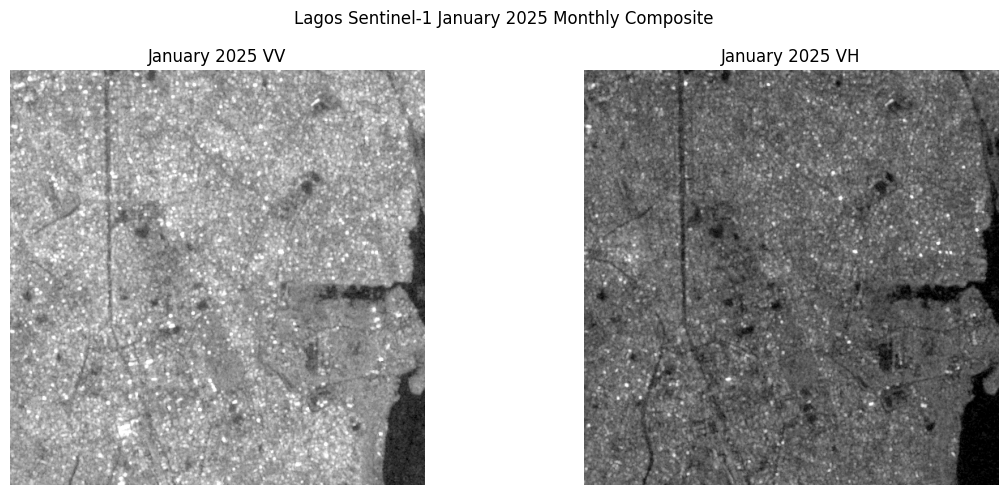


January 2025 prototype input prepared successfully.


In [4]:
# =========================================================
# STEP — Continue January 2025 prototype WITHOUT Lee filter
# =========================================================

import ee
import numpy as np
import matplotlib.pyplot as plt
import requests
from PIL import Image
import io

# Use the already-created January 2025 monthly composite
print("Using January 2025 Sentinel-1 monthly composite")
print("Bands:", monthly_composite.bandNames().getInfo())

# ---------------------------------------------------------
# Download VV and VH as PNGs for prototype inference
# ---------------------------------------------------------

def download_band_png(image, band, min_val=-25, max_val=5, dimensions=512):
    url = image.select(band).getThumbURL({
        "region": aoi,
        "dimensions": dimensions,
        "min": min_val,
        "max": max_val,
        "format": "png"
    })

    response = requests.get(url)
    response.raise_for_status()

    return np.array(
        Image.open(io.BytesIO(response.content)).convert("L"),
        dtype=np.float32
    ) / 255.0


print("Downloading VV...")
vv_png = download_band_png(monthly_composite, "VV")

print("Downloading VH...")
vh_png = download_band_png(monthly_composite, "VH")

print("VV shape:", vv_png.shape)
print("VH shape:", vh_png.shape)

# ---------------------------------------------------------
# Create model input
# ---------------------------------------------------------

model_input = np.stack(
    [vv_png, vh_png],
    axis=0
).astype(np.float32)

print("Model input shape:", model_input.shape)
print("Model input dtype:", model_input.dtype)

print("\nInput statistics:")
print("VV mean:", float(vv_png.mean()))
print("VV median:", float(np.median(vv_png)))
print("VH mean:", float(vh_png.mean()))
print("VH median:", float(np.median(vh_png)))

# ---------------------------------------------------------
# Visualize
# ---------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(vv_png, cmap="gray")
axes[0].set_title("January 2025 VV")
axes[0].axis("off")

axes[1].imshow(vh_png, cmap="gray")
axes[1].set_title("January 2025 VH")
axes[1].axis("off")

plt.suptitle("Lagos Sentinel-1 January 2025 Monthly Composite")
plt.tight_layout()
plt.show()

print("\nJanuary 2025 prototype input prepared successfully.")

Model loaded successfully.
Device: cuda
Model input shape: (1, 2, 512, 512)
Prediction shape: (512, 512)
Predicted classes: [2 5 6]

January 2025 LULC prediction distribution:
Forest            : 0.0000%
Shrubland         : 0.0000%
Savanna           : 0.0008%
Grassland         : 0.0000%
Wetland           : 0.0000%
Cropland          : 0.0118%
Urban/Built-up    : 99.9874%
Barren            : 0.0000%
Water             : 0.0000%


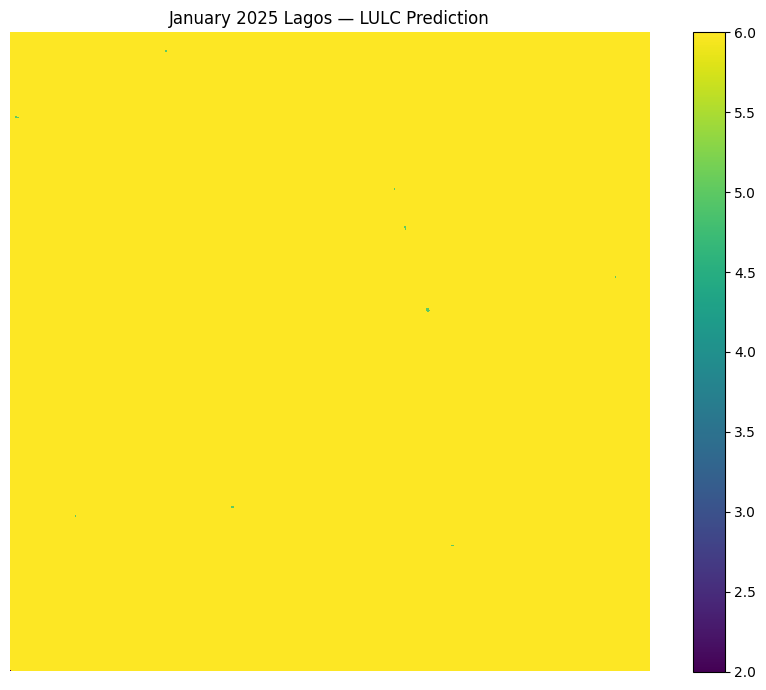

In [6]:
# =========================================================
# January 2025 Lagos — Run trained LULC model
# =========================================================

import sys
import os
import torch
import numpy as np
import matplotlib.pyplot as plt

# Project directory
project_dir = "/home/jovyan/vault/DeepLearningPro"
if project_dir not in sys.path:
    sys.path.insert(0, project_dir)

# Import the actual model definition
from lulc_model import SmallUNet

# ---------------------------------------------------------
# Load trained checkpoint
# ---------------------------------------------------------

checkpoint_path = (
    project_dir +
    "/results/winter9_20261106_094944_502500/best_model.pt"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = SmallUNet(
    num_classes=9,
    in_channels=2
).to(device)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device
)

# Handle checkpoint format
if "model_state_dict" in checkpoint:
    model.load_state_dict(checkpoint["model_state_dict"])
else:
    model.load_state_dict(checkpoint)

model.eval()

print("Model loaded successfully.")
print("Device:", device)

# ---------------------------------------------------------
# Prepare January 2025 Sentinel-1 input
# ---------------------------------------------------------

x = torch.tensor(
    model_input,
    dtype=torch.float32
).unsqueeze(0).to(device)

print("Model input shape:", tuple(x.shape))

# ---------------------------------------------------------
# Inference
# ---------------------------------------------------------

with torch.no_grad():
    logits = model(x)
    prediction = torch.argmax(logits, dim=1)[0].cpu().numpy()

print("Prediction shape:", prediction.shape)
print("Predicted classes:", np.unique(prediction))

# ---------------------------------------------------------
# Class distribution
# ---------------------------------------------------------

class_names = [
    "Forest",
    "Shrubland",
    "Savanna",
    "Grassland",
    "Wetland",
    "Cropland",
    "Urban/Built-up",
    "Barren",
    "Water"
]

print("\nJanuary 2025 LULC prediction distribution:")

for class_id, class_name in enumerate(class_names):
    percentage = (prediction == class_id).mean() * 100
    print(f"{class_name:18s}: {percentage:.4f}%")

# ---------------------------------------------------------
# Visualization
# ---------------------------------------------------------

plt.figure(figsize=(9, 7))
plt.imshow(prediction, interpolation="nearest")
plt.title("January 2025 Lagos — LULC Prediction")
plt.axis("off")
plt.colorbar()
plt.tight_layout()
plt.show()

In [7]:
# =========================================================
# Independent LULC sanity check
# Compare model prediction with ESA WorldCover 2021
# =========================================================

import numpy as np
import pandas as pd

# Model class names
class_names = [
    "Forest",
    "Shrubland",
    "Savanna",
    "Grassland",
    "Wetland",
    "Cropland",
    "Urban/Built-up",
    "Barren",
    "Water"
]

# Model prediction percentages from the current prediction
model_counts = np.bincount(
    prediction.flatten(),
    minlength=len(class_names)
)

model_pct = (
    model_counts / model_counts.sum() * 100
)

# ESA WorldCover 2021 reference percentages
# Values obtained previously for the same Lagos AOI
worldcover_counts = {
    "Forest": 11371.270588235293,
    "Grassland": 3020.674509803918,
    "Cropland": 200.3764705882353,
    "Urban/Built-up": 222164.4039215706,
    "Barren": 465.48235294117643,
    "Water": 9814.811764705892,
    "Wetland": 749.9137254901962,
    "Mangroves": 3003.88235294117
}

wc_total = sum(worldcover_counts.values())

wc_pct = {
    k: v / wc_total * 100
    for k, v in worldcover_counts.items()
}

# Build comparison table
comparison = pd.DataFrame({
    "Class": class_names,
    "Model January 2025 (%)": model_pct,
    "ESA WorldCover 2021 (%)": [
        wc_pct.get("Forest", np.nan),
        np.nan,  # Shrubland not present in retrieved histogram
        np.nan,  # No direct WorldCover Savanna class
        wc_pct.get("Grassland", np.nan),
        wc_pct.get("Wetland", np.nan),
        wc_pct.get("Cropland", np.nan),
        wc_pct.get("Urban/Built-up", np.nan),
        wc_pct.get("Barren", np.nan),
        wc_pct.get("Water", np.nan)
    ]
})

print("\nIndependent LULC sanity check")
print("=" * 70)
print(comparison.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

print("\nImportant:")
print("- WorldCover 2021 is an independent reference, not training data.")
print("- It is from 2021, while the Sentinel-1 model input is January 2025.")
print("- Therefore this is a qualitative sanity check, NOT a formal accuracy score.")
print("- WorldCover Mangroves has no exact equivalent in the 9-class model.")


Independent LULC sanity check
         Class  Model January 2025 (%)  ESA WorldCover 2021 (%)
        Forest                   0.000                    4.534
     Shrubland                   0.000                      NaN
       Savanna                   0.001                      NaN
     Grassland                   0.000                    1.204
       Wetland                   0.000                    0.299
      Cropland                   0.012                    0.080
Urban/Built-up                  99.987                   88.586
        Barren                   0.000                    0.186
         Water                   0.000                    3.914

Important:
- WorldCover 2021 is an independent reference, not training data.
- It is from 2021, while the Sentinel-1 model input is January 2025.
- Therefore this is a qualitative sanity check, NOT a formal accuracy score.
- WorldCover Mangroves has no exact equivalent in the 9-class model.
